# EchoNet-Dynamic: U-Net LV Segmentation → Volume → LVEF → HFrEF

This version preserves the official EchoNet-Dynamic split and the existing pipeline while upgrading the segmentation model to **U-Net**.

New evaluation:
- LV segmentation: **DSC, IoU, HD95**
- LVEF prediction: **MAE, RMSE, R², Pearson r**
- HFrEF classification: **accuracy, precision, recall, F1, AUC**

The HFrEF threshold is configurable in `HFrEF_THRESHOLD` and defaults to **LVEF ≤ 40%**.

The notebook also updates training/runtime optimization, test-case visualizations, metric plots, ROC/confusion matrix, and the schematic flowchart.

In [1]:
# EchoNet-Dynamic + U-Net LV Segmentation + Volume/EF Estimation
# ------------------------------------------------------------------
# Intended for Kaggle with:
#   /kaggle/input/echonet-dynamic-by-stanford-university/
#
# Dataset structure:
#   FileList.csv
#   VolumeTracings.csv
#   Videos/
#
# Pipeline:
#   EchoNet-Dynamic official split
#       -> rasterize expert LV traces
#       -> train 2-D U-Net
#       -> evaluate LV segmentation (DSC, IoU, HD95)
#       -> segment every TEST-frame
#       -> LV area curve / ED-ES detection
#       -> relative LV volume estimation
#       -> LVEF prediction
#       -> LVEF metrics (MAE, RMSE, R², Pearson r)
#       -> HFrEF classification (threshold configurable; default <=40%)
#       -> accuracy, precision, recall, F1, ROC-AUC
#       -> visualizations and 5-case demonstrations
#
# The official TRAIN/VAL/TEST split is never redefined.
# N_TRAIN/N_VAL/N_TEST are optional within-split subsampling controls.
#
# Volume note:
# The standardized 112x112 release does not expose a universal physical pixel
# spacing. Therefore predicted geometric volumes are reported as relative px³.
# EF is scale-invariant and is evaluated against reference EF.
#
# References:
#   https://echonet.github.io/dynamic/
#   https://github.com/echonet/dynamic
#   https://www.kaggle.com/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university

import os
import sys
import math
import time
import random
import warnings
from pathlib import Path
from collections import defaultdict
from contextlib import nullcontext

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from scipy.ndimage import (
    median_filter,
    gaussian_filter1d,
    binary_erosion,
    distance_transform_edt,
)
from scipy.stats import pearsonr
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")


# Config

In [2]:

# ============================================================
# 0. CONFIGURATION
# ============================================================

SEED = 42

# Kaggle input path. The helper below also searches common alternatives.
DATA_ROOT = "/kaggle/input/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university"

# None means ALL eligible studies in that official split.
N_TRAIN = None
N_VAL   = None
N_TEST  = None

# N_TRAIN = 300
# N_VAL   = 100
# N_TEST  = 100

# Number of cases shown in the final visual demonstration.
N_VIS = 5

IMAGE_SIZE = 112
BATCH_SIZE = 32
NUM_WORKERS = 0

EPOCHS = 30
# EPOCHS = 15
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4

# Training optimizations
GRAD_CLIP_NORM = 1.0
EARLY_STOPPING_PATIENCE = 6
MIN_DELTA = 1e-4

# HFrEF classification threshold (reference and predicted LVEF <= threshold).
HFrEF_THRESHOLD = 40.0

# Full-video inference batch size.
INFERENCE_BATCH_SIZE = 64

# Finite HD95 penalty for a completely empty predicted/ground-truth mask.
HD95_EMPTY_PENALTY = float(np.sqrt(IMAGE_SIZE**2 + IMAGE_SIZE**2))

# Optional checkpoint / output directory.
OUTPUT_DIR = Path("/kaggle/working/echonet_unet_results")

# Keep this False for a clean baseline.
USE_AUGMENTATION = False

# Inference:
# - True = segment every frame of each test video.
# - This is the full pipeline requested by the user.
FULL_VIDEO_INFERENCE = True

# ------------------------------------------------------------------
# CUDA COMPATIBILITY CHECK
# ------------------------------------------------------------------
# torch.cuda.is_available() only tells us that a CUDA device is visible.
# It does NOT guarantee that the installed PyTorch wheel contains kernels
# for that GPU's compute capability. A P100 can therefore report
# cuda.is_available() == True and still fail at the first neural-network
# operation with:
#   "CUDA error: no kernel image is available for execution on the device"
#
# We run an actual CUDA kernel before constructing/training the model.
# If that test fails, the pipeline automatically falls back to CPU so that
# the notebook does not crash inside U-Net. For Kaggle, the preferred fix
# is to switch the accelerator to T4x2 and restart the session.
def check_cuda_compatibility():
    if not torch.cuda.is_available():
        return False, "CUDA is not available."

    try:
        gpu_name = torch.cuda.get_device_name(0)
        capability = torch.cuda.get_device_capability(0)
        cuda_build = torch.version.cuda
        arch_list = torch.cuda.get_arch_list()

        print("CUDA diagnostics:")
        print(f"  GPU:              {gpu_name}")
        print(f"  Compute capability: sm_{capability[0]}{capability[1]}")
        print(f"  PyTorch:          {torch.__version__}")
        print(f"  PyTorch CUDA:     {cuda_build}")
        print(f"  PyTorch arch list: {arch_list}")

        # Actually launch a CUDA kernel. This catches architecture/wheel
        # mismatches before any U-Net layer is executed.
        x = torch.randn(8, 8, device="cuda")
        y = (x @ x).sum()
        _ = float(y.item())

        # Clean up the test tensors.
        del x, y
        torch.cuda.empty_cache()

        return True, "CUDA kernel test passed."

    except Exception as exc:
        print("\nCUDA kernel test FAILED:")
        print(f"  {type(exc).__name__}: {exc}")
        return False, str(exc)


CUDA_OK, CUDA_MESSAGE = check_cuda_compatibility()

if CUDA_OK:
    DEVICE = torch.device("cuda")
    print("\nGPU execution enabled.")
else:
    DEVICE = torch.device("cpu")
    print("\nGPU execution disabled for this session.")
    print("The pipeline will continue on CPU.")
    print("For Kaggle, switch Settings → Accelerator to T4x2 and restart the session")
    print("for substantially faster U-Net training.")



CUDA diagnostics:
  GPU:              Tesla T4
  Compute capability: sm_75
  PyTorch:          2.10.0+cu128
  PyTorch CUDA:     12.8
  PyTorch arch list: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']

GPU execution enabled.


# Reproduc

In [3]:

# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Reproducibility is useful for experimentation. These settings can reduce
    # performance slightly on some GPUs.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("STEP 1 — ENVIRONMENT")
print("=" * 80)
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"Device:  {DEVICE}")
print(f"CUDA test: {CUDA_MESSAGE}")
if DEVICE.type == "cuda":
    print(f"GPU:     {torch.cuda.get_device_name(0)}")
print(f"Output:  {OUTPUT_DIR}")
print()


STEP 1 — ENVIRONMENT
Python:  3.12.13
PyTorch: 2.10.0+cu128
Device:  cuda
CUDA test: CUDA kernel test passed.
GPU:     Tesla T4
Output:  /kaggle/working/echonet_unet_results



# Find dataset

In [4]:
# ============================================================
# 2. FIND DATASET
# ============================================================

def find_dataset_root(preferred_root):
    candidates = [
        Path(preferred_root),
        Path("/kaggle/input/echonet-dynamic-by-stanford-university"),
        Path("/kaggle/input/echonet-dynamic"),
        Path("/kaggle/input"),
        Path("."),
    ]

    for root in candidates:
        if not root.exists():
            continue

        # Exact dataset root.
        if (root / "FileList.csv").exists() and (root / "VolumeTracings.csv").exists():
            return root

        # Search one/two levels deep for FileList.csv + VolumeTracings.csv.
        for depth1 in root.iterdir() if root.is_dir() else []:
            if not depth1.is_dir():
                continue
            if (depth1 / "FileList.csv").exists() and (depth1 / "VolumeTracings.csv").exists():
                return depth1
            for depth2 in depth1.iterdir():
                if depth2.is_dir() and (depth2 / "FileList.csv").exists() and (depth2 / "VolumeTracings.csv").exists():
                    return depth2

    raise FileNotFoundError(
        "Could not find FileList.csv and VolumeTracings.csv. "
        "Set DATA_ROOT to the Kaggle input directory containing those files."
    )


DATA_ROOT = find_dataset_root(DATA_ROOT)
VIDEO_DIR = DATA_ROOT / "Videos"

print("=" * 80)
print("STEP 2 — DATASET DISCOVERY")
print("=" * 80)
print(f"Dataset root: {DATA_ROOT}")
print(f"FileList.csv: {DATA_ROOT / 'FileList.csv'}")
print(f"VolumeTracings.csv: {DATA_ROOT / 'VolumeTracings.csv'}")
print(f"Videos directory: {VIDEO_DIR}")
print()




STEP 2 — DATASET DISCOVERY
Dataset root: /kaggle/input/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university/EchoNet-Dynamic
FileList.csv: /kaggle/input/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university/EchoNet-Dynamic/FileList.csv
VolumeTracings.csv: /kaggle/input/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university/EchoNet-Dynamic/VolumeTracings.csv
Videos directory: /kaggle/input/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university/EchoNet-Dynamic/Videos



# Understand dataset

In [5]:
# ============================================================
# 3. UNDERSTAND THE DATASET
# ============================================================

filelist = pd.read_csv(DATA_ROOT / "FileList.csv")
traces_df = pd.read_csv(DATA_ROOT / "VolumeTracings.csv")

print("=" * 80)
print("STEP 3 — UNDERSTAND ECHONET-DYNAMIC")
print("=" * 80)

print("FileList.csv columns:")
print(list(filelist.columns))
print()

print("First 5 FileList rows:")
print(filelist.head())
print()

print("VolumeTracings.csv columns:")
print(list(traces_df.columns))
print()

print("First 5 tracing rows:")
print(traces_df.head())
print()

print(f"Number of FileList rows: {len(filelist):,}")
print(f"Number of tracing rows:  {len(traces_df):,}")

if "Split" in filelist.columns:
    print("\nOfficial split counts in FileList.csv:")
    print(filelist["Split"].astype(str).str.upper().value_counts())

required_filelist_cols = ["FileName", "Split", "EF", "EDV", "ESV"]
missing = [c for c in required_filelist_cols if c not in filelist.columns]
if missing:
    raise ValueError(f"FileList.csv is missing required columns: {missing}")

required_trace_cols = ["FileName", "X1", "Y1", "X2", "Y2", "Frame"]
missing = [c for c in required_trace_cols if c not in traces_df.columns]
if missing:
    raise ValueError(f"VolumeTracings.csv is missing required columns: {missing}")

print("\nExpected conceptual structure:")
print("  • 10,030 A4C echocardiogram videos")
print("  • 112 x 112 standardized video frames")
print("  • FileList.csv: official TRAIN/VAL/TEST split + EF/EDV/ESV")
print("  • VolumeTracings.csv: LV tracing coordinates at key frames")
print("  • Segmentation target: LV cavity")
print()




STEP 3 — UNDERSTAND ECHONET-DYNAMIC
FileList.csv columns:
['FileName', 'EF', 'ESV', 'EDV', 'FrameHeight', 'FrameWidth', 'FPS', 'NumberOfFrames', 'Split']

First 5 FileList rows:
             FileName         EF         ESV         EDV  FrameHeight  \
0  0X100009310A3BD7FC  78.498406   14.881368   69.210534          112   
1  0X1002E8FBACD08477  59.101988   40.383876   98.742884          112   
2  0X1005D03EED19C65B  62.363798   14.267784   37.909734          112   
3  0X10075961BC11C88E  54.545097   33.143084   72.914210          112   
4  0X10094BA0A028EAC3  24.887742  127.581945  169.855024          112   

   FrameWidth  FPS  NumberOfFrames  Split  
0         112   50             174    VAL  
1         112   50             215  TRAIN  
2         112   50             104  TRAIN  
3         112   55             122  TRAIN  
4         112   52             207    VAL  

VolumeTracings.csv columns:
['FileName', 'X1', 'Y1', 'X2', 'Y2', 'Frame']

First 5 tracing rows:
                 File

# INDEX VIDEOS + PARSE TRACES

In [6]:
# ============================================================
# 4. INDEX VIDEOS + PARSE TRACES
# ============================================================

def build_video_index(video_dir):
    if not video_dir.exists():
        raise FileNotFoundError(f"Videos directory not found: {video_dir}")

    valid_ext = {".avi", ".mp4", ".mov", ".m4v"}
    files = [p for p in video_dir.rglob("*") if p.is_file() and p.suffix.lower() in valid_ext]

    # Map both full filename and stem so a .avi/.mp4 conversion mismatch does not break loading.
    index = {}
    for p in files:
        index[p.name] = p
        index[p.stem] = p

    return index


video_index = build_video_index(VIDEO_DIR)
print("=" * 80)
print("STEP 4 — VIDEO INDEX")
print("=" * 80)
print(f"Video files found: {len(video_index):,} index keys")
print(f"Unique video files: {len(set(video_index.values())):,}")
print()

# ------------------------------------------------------------------
# IMPORTANT FILENAME NORMALIZATION
# ------------------------------------------------------------------
# The official EchoNet loader assumes ".avi" when FileList.csv contains
# a filename without an extension. VolumeTracings.csv commonly contains
# the same study with ".avi". We therefore match all sources by a
# canonical study ID (filename stem).
#
# Official reference:
# https://raw.githubusercontent.com/echonet/dynamic/master/echonet/datasets/echo.py
def canonical_id(filename):
    return Path(str(filename).strip()).stem.upper()


# Group tracing rows by CANONICAL study ID -> frame -> coordinate rows.
trace_groups = defaultdict(lambda: defaultdict(list))

for row in traces_df.itertuples(index=False):
    key = canonical_id(row.FileName)
    trace_groups[key][int(row.Frame)].append(
        (float(row.X1), float(row.Y1), float(row.X2), float(row.Y2))
    )

print(f"Videos with tracing annotations: {len(trace_groups):,}")

# Build a canonical-ID -> physical video path index.
video_index_by_id = {}
for p in set(video_index.values()):
    video_index_by_id[canonical_id(p.name)] = p


def resolve_video_path(filename):
    return video_index_by_id.get(canonical_id(filename))


filelist["CanonicalID"] = filelist["FileName"].apply(canonical_id)
filelist["VideoPath"] = filelist["CanonicalID"].apply(lambda k: video_index_by_id.get(k))
filelist["HasTrace"] = filelist["CanonicalID"].isin(trace_groups)

missing_videos = int(filelist["VideoPath"].isna().sum())
missing_traces = int((~filelist["HasTrace"]).sum())

print(f"FileList rows without a matching local video file: {missing_videos:,}")
print(f"FileList rows without a matching VolumeTracings entry: {missing_traces:,}")

print("\nFilename matching examples:")
print(
    filelist[["FileName", "CanonicalID", "VideoPath", "HasTrace"]]
    .head(5)
    .to_string(index=False)
)
print()




STEP 4 — VIDEO INDEX
Video files found: 20,060 index keys
Unique video files: 10,030

Videos with tracing annotations: 10,025
FileList rows without a matching local video file: 0
FileList rows without a matching VolumeTracings entry: 6

Filename matching examples:
          FileName        CanonicalID                                                                                                                  VideoPath  HasTrace
0X100009310A3BD7FC 0X100009310A3BD7FC /kaggle/input/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university/EchoNet-Dynamic/Videos/0X100009310A3BD7FC.mp4      True
0X1002E8FBACD08477 0X1002E8FBACD08477 /kaggle/input/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university/EchoNet-Dynamic/Videos/0X1002E8FBACD08477.mp4      True
0X1005D03EED19C65B 0X1005D03EED19C65B /kaggle/input/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university/EchoNet-Dynamic/Videos/0X1005D03EED19C65B.mp4      True
0X10075961BC11C88E 0X10075961BC11C88E /kaggle/input

# TRACE binary mask

In [7]:
# ============================================================
# 5. TRACE -> BINARY MASK
# ============================================================

def trace_to_mask(trace_rows, height=112, width=112):
    """
    Reconstruct a binary LV cavity mask from the coordinate representation used
    by EchoNet-Dynamic.

    The first coordinate pair encodes the long-axis line. Subsequent pairs
    encode paired short-axis distances. Following the official EchoNet
    implementation, the first pair is excluded when constructing the closed
    polygon.
    """
    if trace_rows is None or len(trace_rows) < 2:
        return np.zeros((height, width), dtype=np.uint8)

    arr = np.asarray(trace_rows, dtype=np.float32)
    x1, y1 = arr[:, 0], arr[:, 1]
    x2, y2 = arr[:, 2], arr[:, 3]

    # Official EchoNet implementation:
    # x = concat(x1[1:], reverse(x2[1:]))
    # y = concat(y1[1:], reverse(y2[1:]))
    x = np.concatenate([x1[1:], x2[1:][::-1]])
    y = np.concatenate([y1[1:], y2[1:][::-1]])

    pts = np.stack([x, y], axis=1)
    pts = np.rint(pts).astype(np.int32)

    pts[:, 0] = np.clip(pts[:, 0], 0, width - 1)
    pts[:, 1] = np.clip(pts[:, 1], 0, height - 1)

    mask = np.zeros((height, width), dtype=np.uint8)
    cv2.fillPoly(mask, [pts], 1)
    return mask


def get_annotated_frames(filename):
    frames_dict = trace_groups.get(canonical_id(filename), {})
    frame_items = []

    for frame_idx, rows in frames_dict.items():
        mask = trace_to_mask(rows, IMAGE_SIZE, IMAGE_SIZE)
        area = int(mask.sum())
        frame_items.append((int(frame_idx), mask, area))

    # Largest mask area = ED candidate; smallest mask area = ES candidate.
    # This is robust to the row order inside VolumeTracings.csv.
    frame_items = sorted(frame_items, key=lambda z: z[2], reverse=True)
    return frame_items


# Build metadata per video with at least two annotated trace frames.
eligible_rows = []

n_split = 0
n_missing_video = 0
n_missing_trace = 0
n_fewer_than_two_frames = 0

for row in filelist.itertuples(index=False):
    split = str(row.Split).strip().upper()

    if split not in {"TRAIN", "VAL", "TEST"}:
        continue

    n_split += 1

    if pd.isna(row.VideoPath):
        n_missing_video += 1
        continue

    frames = get_annotated_frames(row.FileName)

    if len(frames) < 2:
        if len(frames) == 0:
            n_missing_trace += 1
        else:
            n_fewer_than_two_frames += 1
        continue

    # Largest mask = ED, smallest = ES.
    ed_frame, ed_mask, ed_area = frames[0]
    es_frame, es_mask, es_area = frames[-1]

    eligible_rows.append({
        "FileName": row.FileName,
        "CanonicalID": canonical_id(row.FileName),
        "Split": split,
        "EF": float(row.EF),
        "EDV": float(row.EDV),
        "ESV": float(row.ESV),
        "VideoPath": str(row.VideoPath),
        "EDFrame": int(ed_frame),
        "ESFrame": int(es_frame),
        "EDMask": ed_mask,
        "ESMask": es_mask,
        "EDMaskAreaPx": int(ed_area),
        "ESMaskAreaPx": int(es_area),
    })

meta_columns = [
    "FileName", "CanonicalID", "Split", "EF", "EDV", "ESV", "VideoPath",
    "EDFrame", "ESFrame", "EDMask", "ESMask", "EDMaskAreaPx", "ESMaskAreaPx"
]
meta = pd.DataFrame(eligible_rows, columns=meta_columns)

print("=" * 80)
print("STEP 5 — ANNOTATION QA")
print("=" * 80)
print(f"Official TRAIN/VAL/TEST FileList rows: {n_split:,}")
print(f"Missing local videos:                  {n_missing_video:,}")
print(f"Missing tracing entry:                 {n_missing_trace:,}")
print(f"Only 1 tracing frame:                  {n_fewer_than_two_frames:,}")
print(f"Eligible studies with videos + >=2 tracing frames: {len(meta):,}")

if len(meta) == 0:
    raise RuntimeError(
        "No eligible EchoNet-Dynamic studies were matched. "
        "Check the filename diagnostics above. The pipeline now matches "
        "FileList.csv, Videos/, and VolumeTracings.csv by canonical study ID."
    )

print("\nEligible official split counts:")
print(meta["Split"].value_counts())
print()

print("Example annotation summary:")
print(
    meta[[
        "FileName", "Split", "EF", "EDV", "ESV",
        "EDFrame", "ESFrame", "EDMaskAreaPx", "ESMaskAreaPx"
    ]].head()
)
print()




STEP 5 — ANNOTATION QA
Official TRAIN/VAL/TEST FileList rows: 10,030
Missing local videos:                  0
Missing tracing entry:                 6
Only 1 tracing frame:                  0
Eligible studies with videos + >=2 tracing frames: 10,024

Eligible official split counts:
Split
TRAIN    7460
VAL      1288
TEST     1276
Name: count, dtype: int64

Example annotation summary:
             FileName  Split         EF         EDV         ESV  EDFrame  \
0  0X100009310A3BD7FC    VAL  78.498406   69.210534   14.881368       46   
1  0X1002E8FBACD08477  TRAIN  59.101988   98.742884   40.383876        3   
2  0X1005D03EED19C65B  TRAIN  62.363798   37.909734   14.267784       24   
3  0X10075961BC11C88E  TRAIN  54.545097   72.914210   33.143084       91   
4  0X10094BA0A028EAC3    VAL  24.887742  169.855024  127.581945      137   

   ESFrame  EDMaskAreaPx  ESMaskAreaPx  
0       61          1347           560  
1       18          1221           680  
2       35           832          

# VISUALIZE RAW VIDEO + GROUND TRUTH MASKS

STEP 6 — RAW VIDEO + GROUND-TRUTH VISUAL CHECK


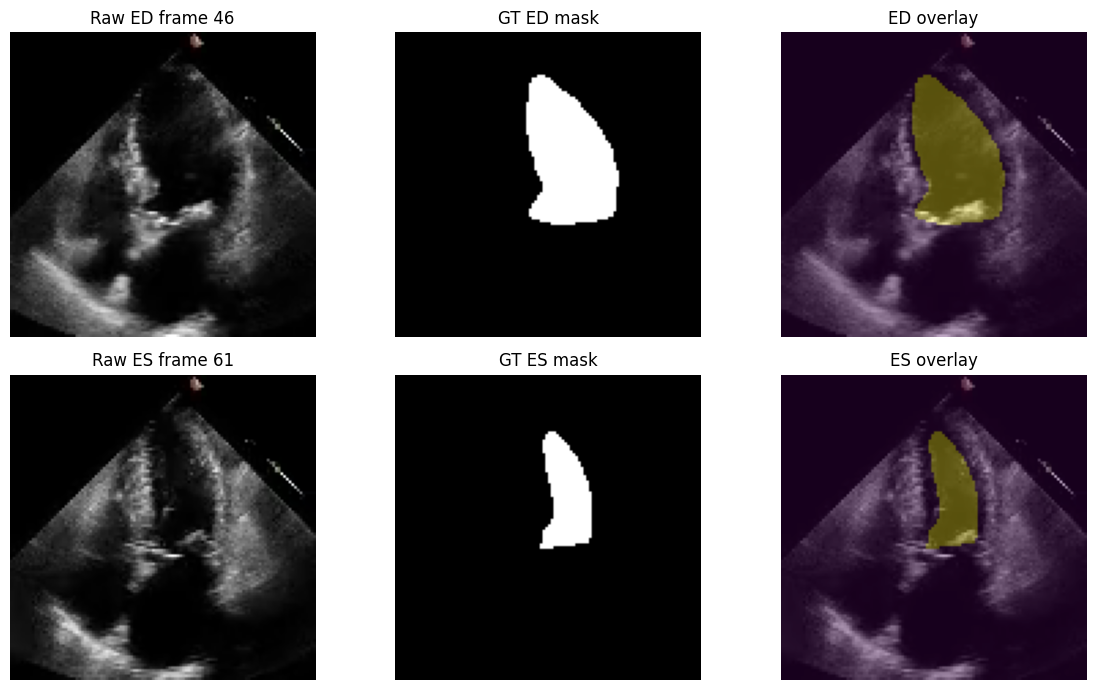

Saved: 01_ground_truth_examples.png



In [8]:
# ============================================================
# 6. VISUALIZE RAW VIDEO + GROUND TRUTH MASKS
# ============================================================

def read_video_frame(video_path, frame_idx):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
    ok, frame = cap.read()
    cap.release()

    if not ok or frame is None:
        raise RuntimeError(f"Could not read frame {frame_idx} from {video_path}")

    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


print("=" * 80)
print("STEP 6 — RAW VIDEO + GROUND-TRUTH VISUAL CHECK")
print("=" * 80)

if len(meta) == 0:
    raise RuntimeError("No eligible annotated studies were found.")

sample_meta = meta.iloc[0]
img_ed = read_video_frame(sample_meta.VideoPath, sample_meta.EDFrame)
img_es = read_video_frame(sample_meta.VideoPath, sample_meta.ESFrame)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

axes[0, 0].imshow(img_ed, cmap="gray")
axes[0, 0].set_title(f"Raw ED frame {sample_meta.EDFrame}")
axes[0, 0].axis("off")

axes[0, 1].imshow(sample_meta.EDMask, cmap="gray")
axes[0, 1].set_title("GT ED mask")
axes[0, 1].axis("off")

axes[0, 2].imshow(img_ed)
axes[0, 2].imshow(sample_meta.EDMask, alpha=0.35)
axes[0, 2].set_title("ED overlay")
axes[0, 2].axis("off")

axes[1, 0].imshow(img_es)
axes[1, 0].set_title(f"Raw ES frame {sample_meta.ESFrame}")
axes[1, 0].axis("off")

axes[1, 1].imshow(sample_meta.ESMask, cmap="gray")
axes[1, 1].set_title("GT ES mask")
axes[1, 1].axis("off")

axes[1, 2].imshow(img_es)
axes[1, 2].imshow(sample_meta.ESMask, alpha=0.35)
axes[1, 2].set_title("ES overlay")
axes[1, 2].axis("off")

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "01_ground_truth_examples.png", dpi=180, bbox_inches="tight")
plt.show()

print("Saved: 01_ground_truth_examples.png")
print()




# TRAIN/VAL/TEST SUBSETTING WITHOUT CHANGING OFFICIAL SPLIT

In [9]:
# ============================================================
# 7. TRAIN/VAL/TEST SUBSETTING WITHOUT CHANGING OFFICIAL SPLIT
# ============================================================

def select_within_official_split(df, split, n, seed=42):
    split_df = df[df["Split"] == split].copy().reset_index(drop=True)

    # n=None => all
    if n is None or n >= len(split_df):
        return split_df

    rng = np.random.default_rng(seed)
    idx = rng.choice(len(split_df), size=int(n), replace=False)
    return split_df.iloc[np.sort(idx)].reset_index(drop=True)


train_meta = select_within_official_split(meta, "TRAIN", N_TRAIN, SEED)
val_meta   = select_within_official_split(meta, "VAL",   N_VAL,   SEED + 1)
test_meta  = select_within_official_split(meta, "TEST",  N_TEST,  SEED + 2)

print("=" * 80)
print("STEP 7 — FINAL STUDY COUNTS")
print("=" * 80)
print(f"Official TRAIN eligible: {sum(meta.Split == 'TRAIN'):,}")
print(f"Official VAL eligible:   {sum(meta.Split == 'VAL'):,}")
print(f"Official TEST eligible:  {sum(meta.Split == 'TEST'):,}")
print()
print(f"Using TRAIN: {len(train_meta):,}  (N_TRAIN={N_TRAIN})")
print(f"Using VAL:   {len(val_meta):,}  (N_VAL={N_VAL})")
print(f"Using TEST:  {len(test_meta):,}  (N_TEST={N_TEST})")
print()
print("No cross-split rebalancing/redefinition was performed.")
print()




STEP 7 — FINAL STUDY COUNTS
Official TRAIN eligible: 7,460
Official VAL eligible:   1,288
Official TEST eligible:  1,276

Using TRAIN: 7,460  (N_TRAIN=None)
Using VAL:   1,288  (N_VAL=None)
Using TEST:  1,276  (N_TEST=None)

No cross-split rebalancing/redefinition was performed.



# Pytorch Dataset

In [10]:
# ============================================================
# 8. PYTORCH DATASET
# ============================================================

def normalize_image(image_rgb):
    """
    112x112 RGB echo frame -> float tensor CxHxW.
    We convert to grayscale because the underlying echocardiogram is grayscale.
    """
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
    gray = (gray - 0.5) / 0.5
    return torch.from_numpy(gray[None, ...]).float()


class EchoNetSegmentationDataset(Dataset):
    def __init__(self, metadata_df, use_augmentation=False):
        self.df = metadata_df.reset_index(drop=True)
        self.use_augmentation = use_augmentation

        self.samples = []
        for _, row in self.df.iterrows():
            self.samples.append({
                "FileName": row.FileName,
                "VideoPath": row.VideoPath,
                "Frame": int(row.EDFrame),
                "Mask": row.EDMask.astype(np.float32),
                "Phase": "ED",
            })
            self.samples.append({
                "FileName": row.FileName,
                "VideoPath": row.VideoPath,
                "Frame": int(row.ESFrame),
                "Mask": row.ESMask.astype(np.float32),
                "Phase": "ES",
            })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]

        image = read_video_frame(item["VideoPath"], item["Frame"])
        mask = item["Mask"].copy()

        if self.use_augmentation and random.random() < 0.5:
            image = np.ascontiguousarray(image[:, ::-1])
            mask = np.ascontiguousarray(mask[:, ::-1])

        image = normalize_image(image)
        mask = torch.from_numpy(mask[None, ...]).float()

        return {
            "image": image,
            "mask": mask,
            "filename": item["FileName"],
            "frame": item["Frame"],
            "phase": item["Phase"],
        }


print("=" * 80)
print("STEP 8 — DATA LOADERS")
print("=" * 80)

train_ds = EchoNetSegmentationDataset(train_meta, USE_AUGMENTATION)
val_ds   = EchoNetSegmentationDataset(val_meta, USE_AUGMENTATION)
test_ds  = EchoNetSegmentationDataset(test_meta, False)

print(f"Training annotated frames:   {len(train_ds):,}")
print(f"Validation annotated frames: {len(val_ds):,}")
print(f"Test annotated frames:       {len(test_ds):,}")
print(f"DataLoader workers:           {NUM_WORKERS}")

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=(NUM_WORKERS if DEVICE.type == "cuda" else 0), pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=(NUM_WORKERS if DEVICE.type == "cuda" else 0), pin_memory=(DEVICE.type == "cuda")
)

batch = next(iter(train_loader))
print()
print("First training batch:")
print("  images:", tuple(batch["image"].shape))
print("  masks: ", tuple(batch["mask"].shape))
print("  dtype: ", batch["image"].dtype)
print("  min/max image:", float(batch["image"].min()), float(batch["image"].max()))
print()




STEP 8 — DATA LOADERS
Training annotated frames:   14,920
Validation annotated frames: 2,576
Test annotated frames:       2,552
DataLoader workers:           0

First training batch:
  images: (32, 1, 112, 112)
  masks:  (32, 1, 112, 112)
  dtype:  torch.float32
  min/max image: -1.0 1.0



# U-Net

In [11]:
# ============================================================
# 9. U-NET MODEL
# ============================================================

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_ch,
                out_ch,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(
                out_ch
            ),
            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_ch,
                out_ch,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(
                out_ch
            ),
            nn.ReLU(
                inplace=True
            )
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """
    Standard 2-D U-Net for LV cavity segmentation.

    Encoder:
        1 -> 32 -> 64 -> 128 -> 256 -> 512

    Decoder:
        512 -> 256 -> 128 -> 64 -> 32

    Skip connections preserve spatial information needed for
    accurate LV boundary delineation.
    """

    def __init__(
        self,
        in_channels=1,
        out_channels=1,
        base_channels=32
    ):
        super().__init__()

        f = base_channels

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Encoder
        self.enc1 = DoubleConv(
            in_channels,
            f
        )

        self.enc2 = DoubleConv(
            f,
            f * 2
        )

        self.enc3 = DoubleConv(
            f * 2,
            f * 4
        )

        self.enc4 = DoubleConv(
            f * 4,
            f * 8
        )

        self.bottleneck = DoubleConv(
            f * 8,
            f * 16
        )

        # Decoder
        self.up4 = nn.ConvTranspose2d(
            f * 16,
            f * 8,
            kernel_size=2,
            stride=2
        )

        self.dec4 = DoubleConv(
            f * 16,
            f * 8
        )

        self.up3 = nn.ConvTranspose2d(
            f * 8,
            f * 4,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            f * 8,
            f * 4
        )

        self.up2 = nn.ConvTranspose2d(
            f * 4,
            f * 2,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            f * 4,
            f * 2
        )

        self.up1 = nn.ConvTranspose2d(
            f * 2,
            f,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            f * 2,
            f
        )

        self.head = nn.Conv2d(
            f,
            out_channels,
            kernel_size=1
        )

        self._initialize_weights()

    def _initialize_weights(self):
        """
        Kaiming initialization is well suited to ReLU-based convolutional
        networks and provides a stable starting point for segmentation.
        """
        for module in self.modules():

            if isinstance(
                module,
                nn.Conv2d
            ):
                nn.init.kaiming_normal_(
                    module.weight,
                    mode="fan_out",
                    nonlinearity="relu"
                )

                if module.bias is not None:
                    nn.init.zeros_(
                        module.bias
                    )

            elif isinstance(
                module,
                nn.ConvTranspose2d
            ):
                nn.init.kaiming_normal_(
                    module.weight,
                    mode="fan_out",
                    nonlinearity="relu"
                )

                if module.bias is not None:
                    nn.init.zeros_(
                        module.bias
                    )

            elif isinstance(
                module,
                nn.BatchNorm2d
            ):
                nn.init.ones_(
                    module.weight
                )

                nn.init.zeros_(
                    module.bias
                )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        b = self.bottleneck(
            self.pool(e4)
        )

        d4 = self.up4(b)

        d4 = torch.cat(
            [
                d4,
                e4
            ],
            dim=1
        )

        d4 = self.dec4(d4)

        d3 = self.up3(d4)

        d3 = torch.cat(
            [
                d3,
                e3
            ],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [
                d2,
                e2
            ],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [
                d1,
                e1
            ],
            dim=1
        )

        d1 = self.dec1(d1)

        return self.head(d1)


model = UNet(
    in_channels=1,
    out_channels=1,
    base_channels=32
).to(DEVICE)

print("=" * 80)
print("STEP 9 — U-NET MODEL")
print("=" * 80)
print(model)
print()

print(
    f"Trainable parameters: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)
print()

# Quick shape sanity-check before training.
with torch.no_grad():

    test_x = torch.zeros(
        2,
        1,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=DEVICE
    )

    test_y = model(
        test_x
    )

    print(
        f"Input test shape:  "
        f"{tuple(test_x.shape)}"
    )

    print(
        f"Output test shape: "
        f"{tuple(test_y.shape)}"
    )

    assert (
        test_y.shape == test_x.shape
    ), "U-Net output shape does not match input."

    del test_x, test_y

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

print(
    "U-Net forward-pass sanity check: PASSED"
)
print()


STEP 9 — U-NET MODEL
UNet(
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, t

# Loss, Segmentation Metrics, and Supporting Functions

In [12]:
# ============================================================
# 10. LOSS + SEGMENTATION METRICS
# ============================================================

def dice_coefficient_from_probs(probs, targets, eps=1e-7):
    probs = probs.float()
    targets = targets.float()

    dims = tuple(range(1, probs.ndim))
    intersection = (probs * targets).sum(dim=dims)
    denom = probs.sum(dim=dims) + targets.sum(dim=dims)

    dice = (2.0 * intersection + eps) / (denom + eps)
    return dice.mean()


def dice_loss(logits, targets):
    return 1.0 - dice_coefficient_from_probs(torch.sigmoid(logits), targets)


def combined_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    dloss = dice_loss(logits, targets)
    return 0.5 * bce + 0.5 * dloss


def binary_dice_np(pred_mask, true_mask, eps=1e-7):
    pred = np.asarray(pred_mask).astype(bool)
    true = np.asarray(true_mask).astype(bool)

    pred_sum = pred.sum()
    true_sum = true.sum()

    if pred_sum == 0 and true_sum == 0:
        return 1.0

    inter = np.logical_and(pred, true).sum()

    return float(
        (2.0 * inter + eps)
        / (pred_sum + true_sum + eps)
    )


def binary_iou_np(pred_mask, true_mask, eps=1e-7):
    pred = np.asarray(pred_mask).astype(bool)
    true = np.asarray(true_mask).astype(bool)

    union = np.logical_or(pred, true).sum()

    if union == 0:
        return 1.0

    inter = np.logical_and(pred, true).sum()

    return float(
        (inter + eps)
        / (union + eps)
    )


def hd95_np(pred_mask, true_mask):
    """
    Symmetric 95th-percentile Hausdorff distance between segmentation surfaces.

    Returned unit: pixels, because the standardized EchoNet release is 112x112.

    Empty-mask handling:
        • both masks empty -> 0 pixels
        • exactly one mask empty -> image-diagonal penalty
    """
    pred = np.asarray(pred_mask).astype(bool)
    true = np.asarray(true_mask).astype(bool)

    pred_empty = not pred.any()
    true_empty = not true.any()

    if pred_empty and true_empty:
        return 0.0

    if pred_empty or true_empty:
        return float(HD95_EMPTY_PENALTY)

    pred_surface = pred ^ binary_erosion(
        pred,
        structure=np.ones((3, 3), dtype=bool),
        border_value=0,
    )

    true_surface = true ^ binary_erosion(
        true,
        structure=np.ones((3, 3), dtype=bool),
        border_value=0,
    )

    if not pred_surface.any() or not true_surface.any():
        return float(HD95_EMPTY_PENALTY)

    dt_true = distance_transform_edt(~true_surface)
    dt_pred = distance_transform_edt(~pred_surface)

    d_pred_to_true = dt_true[pred_surface]
    d_true_to_pred = dt_pred[true_surface]

    distances = np.concatenate(
        [d_pred_to_true, d_true_to_pred]
    )

    return float(
        np.percentile(distances, 95)
    )


def safe_pearson(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    if len(y_true) < 2:
        return np.nan

    if np.std(y_true) < 1e-12 or np.std(y_pred) < 1e-12:
        return np.nan

    return float(
        pearsonr(y_true, y_pred).statistic
    )


def safe_r2(y_true, y_pred):
    if len(y_true) < 2:
        return np.nan

    return float(
        r2_score(y_true, y_pred)
    )


def safe_auc(y_true, continuous_hf_score):
    y_true = np.asarray(y_true).astype(int)
    continuous_hf_score = np.asarray(
        continuous_hf_score,
        dtype=float
    )

    if len(np.unique(y_true)) < 2:
        return np.nan

    return float(
        roc_auc_score(
            y_true,
            continuous_hf_score
        )
    )


def segmentation_metrics(pred_mask, true_mask):
    return {
        "DSC": binary_dice_np(
            pred_mask,
            true_mask
        ),
        "IoU": binary_iou_np(
            pred_mask,
            true_mask
        ),
        "HD95_px": hd95_np(
            pred_mask,
            true_mask
        ),
    }


# Metric sanity checks.
_test_true = np.zeros(
    (IMAGE_SIZE, IMAGE_SIZE),
    dtype=np.uint8
)

_test_pred = np.zeros_like(
    _test_true
)

_test_true[30:60, 35:65] = 1
_test_pred[31:61, 36:66] = 1

print("Segmentation metrics initialized:")
print("  • DSC (Dice similarity coefficient) — higher is better")
print("  • IoU (intersection-over-union) — higher is better")
print("  • HD95 (95th-percentile Hausdorff distance, pixels) — lower is better")
print()
print(
    f"Metric smoke test — "
    f"DSC={binary_dice_np(_test_pred, _test_true):.4f}, "
    f"IoU={binary_iou_np(_test_pred, _test_true):.4f}, "
    f"HD95={hd95_np(_test_pred, _test_true):.2f}px"
)
print(
    f"Empty-mask HD95 penalty: "
    f"{hd95_np(_test_pred * 0, _test_true):.2f}px"
)
print()


Segmentation metrics initialized:
  • DSC (Dice similarity coefficient) — higher is better
  • IoU (intersection-over-union) — higher is better
  • HD95 (95th-percentile Hausdorff distance, pixels) — lower is better

Metric smoke test — DSC=0.9344, IoU=0.8770, HD95=1.00px
Empty-mask HD95 penalty: 158.39px



# Training / Validation

In [13]:
# ============================================================
# 11. TRAINING / VALIDATION — U-NET
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    betas=(0.9, 0.999)
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

AMP_ENABLED = DEVICE.type == "cuda"

if AMP_ENABLED:
    if hasattr(
        torch,
        "amp"
    ) and hasattr(
        torch.amp,
        "GradScaler"
    ):
        scaler = torch.amp.GradScaler(
            "cuda",
            enabled=True
        )
    else:
        scaler = torch.cuda.amp.GradScaler(
            enabled=True
        )
else:
    scaler = None


def autocast_context():

    if AMP_ENABLED:

        if hasattr(
            torch,
            "amp"
        ) and hasattr(
            torch.amp,
            "autocast"
        ):
            return torch.amp.autocast(
                "cuda",
                dtype=torch.float16
            )

        return torch.cuda.amp.autocast(
            enabled=True
        )

    return nullcontext()


history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": [],
    "lr": []
}

best_val_loss = float(
    "inf"
)

best_model_path = (
    OUTPUT_DIR
    / "best_unet.pt"
)

epochs_without_improvement = 0


print("=" * 80)
print("STEP 10 — TRAIN U-NET")
print("=" * 80)

print(
    f"Epochs:              {EPOCHS}"
)

print(
    f"Device:              {DEVICE}"
)

print(
    f"Optimizer:           AdamW"
)

print(
    f"Learning rate:       "
    f"{LEARNING_RATE}"
)

print(
    f"Weight decay:        "
    f"{WEIGHT_DECAY}"
)

print(
    f"Mixed precision:     "
    f"{AMP_ENABLED}"
)

print(
    f"Gradient clip norm:  "
    f"{GRAD_CLIP_NORM}"
)

print(
    f"Early-stop patience: "
    f"{EARLY_STOPPING_PATIENCE}"
)

print()


if DEVICE.type == "cpu":

    print(
        "NOTE: Training is running on CPU."
    )

    print(
        "For Kaggle, T4x2 is recommended "
        "for practical U-Net training time."
    )

    print()


for epoch in range(
    1,
    EPOCHS + 1
):

    # -------------------------------
    # TRAIN
    # -------------------------------

    model.train()

    running_train_loss = 0.0

    start_time = time.time()

    for batch in tqdm(
        train_loader,
        desc=(
            f"Epoch {epoch}/{EPOCHS} "
            "[train]"
        ),
        leave=False
    ):

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch[
            "mask"
        ].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with autocast_context():

            logits = model(
                images
            )

            loss = combined_loss(
                logits,
                masks
            )

        if AMP_ENABLED:

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP_NORM
            )

            scaler.step(
                optimizer
            )

            scaler.update()

        else:

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP_NORM
            )

            optimizer.step()

        running_train_loss += (
            float(
                loss.detach().item()
            )
            * images.size(0)
        )

    train_loss = (
        running_train_loss
        / max(
            len(train_ds),
            1
        )
    )

    # -------------------------------
    # VALIDATE
    # -------------------------------

    model.eval()

    running_val_loss = 0.0

    val_dices = []
    val_ious = []

    with torch.no_grad():

        for batch in tqdm(
            val_loader,
            desc=(
                f"Epoch {epoch}/{EPOCHS} "
                "[val]"
            ),
            leave=False
        ):

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )

            masks = batch[
                "mask"
            ].to(
                DEVICE,
                non_blocking=True
            )

            with autocast_context():

                logits = model(
                    images
                )

                loss = combined_loss(
                    logits,
                    masks
                )

            probs = torch.sigmoid(
                logits
            )

            preds = (
                probs >= 0.5
            ).float()

            running_val_loss += (
                float(
                    loss.detach().item()
                )
                * images.size(0)
            )

            for p, y in zip(
                preds[
                    :, 0
                ].cpu().numpy(),
                masks[
                    :, 0
                ].cpu().numpy()
            ):

                val_dices.append(
                    binary_dice_np(
                        p,
                        y
                    )
                )

                val_ious.append(
                    binary_iou_np(
                        p,
                        y
                    )
                )

    val_loss = (
        running_val_loss
        / max(
            len(val_ds),
            1
        )
    )

    val_dice = (
        float(
            np.mean(
                val_dices
            )
        )
        if val_dices
        else np.nan
    )

    val_iou = (
        float(
            np.mean(
                val_ious
            )
        )
        if val_ious
        else np.nan
    )

    scheduler.step(
        val_loss
    )

    current_lr = float(
        optimizer.param_groups[0]["lr"]
    )

    history[
        "train_loss"
    ].append(
        train_loss
    )

    history[
        "val_loss"
    ].append(
        val_loss
    )

    history[
        "val_dice"
    ].append(
        val_dice
    )

    history[
        "val_iou"
    ].append(
        val_iou
    )

    history[
        "lr"
    ].append(
        current_lr
    )

    improved = (
        val_loss
        < (
            best_val_loss
            - MIN_DELTA
        )
    )

    if improved:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),

                "epoch":
                    epoch,

                "val_loss":
                    val_loss,

                "val_dice":
                    val_dice,

                "val_iou":
                    val_iou,

                "config": {
                    "model":
                        "U-Net",

                    "image_size":
                        IMAGE_SIZE,

                    "batch_size":
                        BATCH_SIZE,

                    "lr":
                        LEARNING_RATE,

                    "weight_decay":
                        WEIGHT_DECAY,

                    "optimizer":
                        "AdamW",

                    "initialization":
                        "Kaiming",
                }
            },
            best_model_path
        )

    else:

        epochs_without_improvement += 1

    elapsed = (
        time.time()
        - start_time
    )

    print(
        f"Epoch {epoch:02d} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"val_DSC={val_dice:.4f} | "
        f"val_IoU={val_iou:.4f} | "
        f"lr={current_lr:.2e} | "
        f"no-improve="
        f"{epochs_without_improvement}/"
        f"{EARLY_STOPPING_PATIENCE} | "
        f"time={elapsed/60:.1f} min"
    )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            f"Early stopping triggered "
            f"at epoch {epoch}."
        )

        break


print()

print(
    f"Best validation loss: "
    f"{best_val_loss:.4f}"
)

print(
    f"Saved best checkpoint: "
    f"{best_model_path}"
)

print()


STEP 10 — TRAIN U-NET
Epochs:              30
Device:              cuda
Optimizer:           AdamW
Learning rate:       0.0002
Weight decay:        0.0001
Mixed precision:     True
Gradient clip norm:  1.0
Early-stop patience: 6



Epoch 1/30 [train]:   0%|          | 0/467 [00:00<?, ?it/s]

Epoch 1/30 [val]:   0%|          | 0/81 [00:00<?, ?it/s]

Epoch 01 | train_loss=0.1794 | val_loss=0.0753 | val_DSC=0.9122 | val_IoU=0.8417 | lr=2.00e-04 | no-improve=0/6 | time=5.1 min


Epoch 2/30 [train]:   0%|          | 0/467 [00:00<?, ?it/s]

...

Epoch 10/30 [val]:   0%|          | 0/81 [00:00<?, ?it/s]

Epoch 10 | train_loss=0.0374 | val_loss=0.0676 | val_DSC=0.9218 | val_IoU=0.8576 | lr=1.00e-04 | no-improve=5/6 | time=4.7 min


Epoch 11/30 [train]:   0%|          | 0/467 [00:00<?, ?it/s]

Epoch 11/30 [val]:   0%|          | 0/81 [00:00<?, ?it/s]

Epoch 11 | train_loss=0.0341 | val_loss=0.0691 | val_DSC=0.9215 | val_IoU=0.8571 | lr=5.00e-05 | no-improve=6/6 | time=4.7 min
Early stopping triggered at epoch 11.

Best validation loss: 0.0639
Saved best checkpoint: /kaggle/working/echonet_unet_results/best_unet.pt



# Training Curves

STEP 11 — TRAINING CURVES


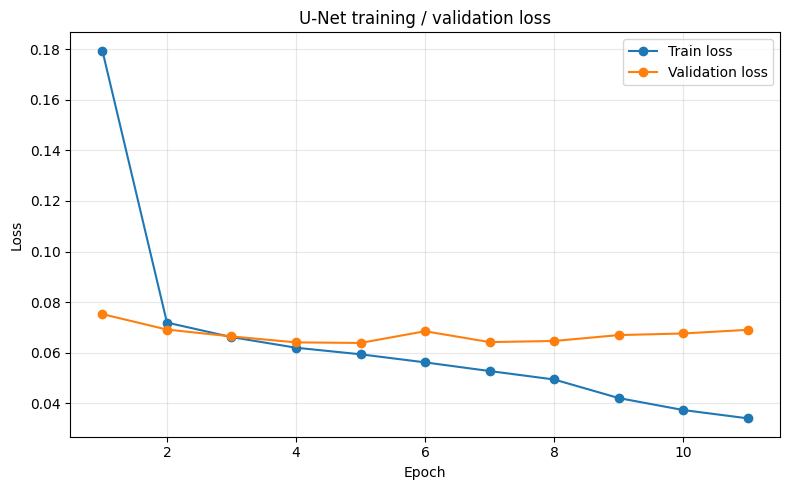

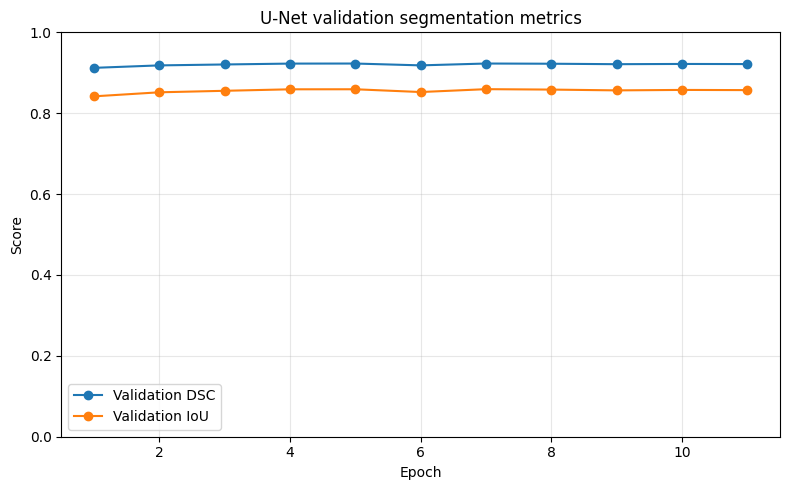

Saved:
  02_training_loss.png
  03_validation_segmentation_metrics.png



In [14]:
# ============================================================
# 12. TRAINING CURVES
# ============================================================

print("=" * 80)
print("STEP 11 — TRAINING CURVES")
print("=" * 80)

epochs_axis = np.arange(1, len(history["train_loss"]) + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epochs_axis, history["train_loss"], marker="o", label="Train loss")
ax.plot(epochs_axis, history["val_loss"], marker="o", label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("U-Net training / validation loss")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "02_training_loss.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epochs_axis, history["val_dice"], marker="o", label="Validation DSC")
ax.plot(epochs_axis, history["val_iou"], marker="o", label="Validation IoU")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("U-Net validation segmentation metrics")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "03_validation_segmentation_metrics.png", dpi=180, bbox_inches="tight")
plt.show()

print("Saved:")
print("  02_training_loss.png")
print("  03_validation_segmentation_metrics.png")
print()


# Load Best U-Net Model

In [15]:
# ============================================================
# 13. LOAD BEST U-NET MODEL
# ============================================================

print("=" * 80)
print("STEP 12 — LOAD BEST U-NET CHECKPOINT")
print("=" * 80)

checkpoint = torch.load(best_model_path, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Loaded epoch:          {checkpoint['epoch']}")
print(f"Loaded validation loss:{checkpoint['val_loss']:.4f}")
print(f"Loaded validation DSC: {checkpoint.get('val_dice', np.nan):.4f}")
print(f"Loaded validation IoU: {checkpoint.get('val_iou', np.nan):.4f}")
print()


STEP 12 — LOAD BEST U-NET CHECKPOINT
Loaded epoch:          5
Loaded validation loss:0.0639
Loaded validation DSC: 0.9228
Loaded validation IoU: 0.8592



# Video Reading / Frame-Batch Inference

In [16]:
# ============================================================
# 14. VIDEO READING / FRAME-BATCH INFERENCE
# ============================================================

def read_video_rgb(video_path):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        if frame.shape[0] != IMAGE_SIZE or frame.shape[1] != IMAGE_SIZE:
            frame = cv2.resize(frame, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
        frames.append(frame)

    cap.release()

    if len(frames) == 0:
        raise RuntimeError(f"No frames read from video: {video_path}")

    return np.stack(frames, axis=0)


def preprocess_frames_for_model(frames_rgb):
    """
    Batch preprocessing to reduce Python-loop overhead.
    """
    gray_frames = np.stack(
        [
            cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
            for frame in frames_rgb
        ],
        axis=0,
    )

    gray_frames = (gray_frames - 0.5) / 0.5
    return torch.from_numpy(gray_frames[:, None, :, :]).float()


@torch.inference_mode()
def segment_video(video_path, inference_batch_size=INFERENCE_BATCH_SIZE):
    frames = read_video_rgb(video_path)
    x = preprocess_frames_for_model(frames)

    all_probs = []
    all_masks = []

    for start in range(0, len(x), inference_batch_size):
        xb = x[start:start + inference_batch_size].to(DEVICE)
        with autocast_context():
            logits = model(xb)
        probs = torch.sigmoid(logits).cpu().numpy()[:, 0]
        masks = (probs >= 0.5).astype(np.uint8)

        all_probs.append(probs)
        all_masks.append(masks)

    probs = np.concatenate(all_probs, axis=0)
    masks = np.concatenate(all_masks, axis=0)

    areas = masks.reshape(len(masks), -1).sum(axis=1).astype(float)

    return frames, probs, masks, areas


def smooth_area_curve(area_curve):
    area_curve = np.asarray(area_curve, dtype=float)

    if len(area_curve) < 7:
        return area_curve.copy()

    # Remove single-frame spikes first.
    med = median_filter(area_curve, size=5, mode="nearest")

    # Additional gentle smoothing.
    sigma = min(1.2, max(0.6, len(area_curve) / 300.0))
    smooth = gaussian_filter1d(med, sigma=sigma, mode="nearest")

    return smooth


def identify_ed_es(area_curve):
    smooth = smooth_area_curve(area_curve)

    # Exclude tiny boundary regions where video acquisition can contain
    # black/transition frames.
    n = len(smooth)
    margin = max(1, int(round(0.02 * n)))

    search = smooth[margin:max(margin + 1, n - margin)]

    ed_local = int(np.argmax(search))
    es_local = int(np.argmin(search))

    ed_frame = ed_local + margin
    es_frame = es_local + margin

    return ed_frame, es_frame, smooth




# Volume Estimation

In [17]:
# ============================================================
# 15. VOLUME ESTIMATION
# ============================================================

def mask_area(mask):
    return float(np.asarray(mask, dtype=np.uint8).sum())


def long_axis_length_from_mask(mask):
    """
    Estimate a 2-D LV long-axis length from the mask using PCA.

    This is a practical geometry-only approximation for a predicted mask.
    It is intentionally not treated as a physical cm/mm measurement.
    """
    ys, xs = np.where(mask > 0)

    if len(xs) < 10:
        return np.nan

    pts = np.column_stack([xs.astype(np.float64), ys.astype(np.float64)])
    pts -= pts.mean(axis=0, keepdims=True)

    cov = np.cov(pts.T)
    eigvals, eigvecs = np.linalg.eigh(cov)
    axis = eigvecs[:, np.argmax(eigvals)]

    projection = pts @ axis
    length = float(projection.max() - projection.min())

    return max(length, 1.0)


def area_length_volume(mask):
    """
    Single-plane area-length LV volume estimate:
        V = (8 / (3*pi)) * A^2 / L

    Returned unit is pixel^3 because the released 112x112 frames do not expose
    a universal physical pixel spacing. EF remains scale-invariant.
    """
    A = mask_area(mask)
    L = long_axis_length_from_mask(mask)

    if A <= 0 or not np.isfinite(L) or L <= 0:
        return np.nan

    V = (8.0 / (3.0 * np.pi)) * (A ** 2) / L
    return float(V)


def _mask_profile(mask, n_slices=21):
    """
    Convert a binary LV mask into a diameter-vs-position profile along its
    principal (long) axis.

    At each longitudinal position, the mask width perpendicular to the long
    axis is treated as an approximate LV diameter. A circular cross-section
    with that diameter is then used for Simpson-style disc integration.
    """
    ys, xs = np.where(mask > 0)

    if len(xs) < 10:
        return None, None

    pts = np.column_stack([xs.astype(np.float64), ys.astype(np.float64)])
    center = pts.mean(axis=0)
    centered = pts - center

    cov = np.cov(centered.T)
    eigvals, eigvecs = np.linalg.eigh(cov)
    long_axis = eigvecs[:, np.argmax(eigvals)]

    # Make the second axis orthogonal.
    short_axis = np.array([-long_axis[1], long_axis[0]], dtype=np.float64)

    u = centered @ long_axis
    v = centered @ short_axis

    u_min, u_max = float(u.min()), float(u.max())
    if u_max - u_min < 2:
        return None, None

    # Fine bins stabilize the width estimates.
    n_bins = max(40, min(140, int(round((u_max - u_min) * 1.5))))
    edges = np.linspace(u_min, u_max, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    widths = np.full(n_bins, np.nan, dtype=np.float64)

    bin_ids = np.clip(np.digitize(u, edges) - 1, 0, n_bins - 1)
    for b in range(n_bins):
        vb = v[bin_ids == b]
        if len(vb) >= 2:
            widths[b] = float(vb.max() - vb.min())

    good = np.isfinite(widths) & (widths > 0)
    if good.sum() < 5:
        return None, None

    # Interpolate missing widths.
    widths = np.interp(
        centers,
        centers[good],
        widths[good],
    )

    # Mild smoothing prevents jagged masks from causing huge disk fluctuations.
    widths = gaussian_filter1d(widths, sigma=1.0, mode="nearest")

    target_u = np.linspace(u_min, u_max, n_slices)
    target_d = np.interp(target_u, centers, widths)

    return target_u, np.maximum(target_d, 0.5)


def simpson_volume(mask, n_slices=21):
    """
    Approximate single-plane Simpson disc summation from a predicted LV mask.

    For each longitudinal position:
        disk_area = pi * (diameter / 2)^2

    The disk areas are integrated along the long axis with Simpson's rule.
    The result is pixel^3. This is intended for relative volume estimation and
    EF calculation, not as a physically calibrated clinical volume in mL.
    """
    u, diameter = _mask_profile(mask, n_slices=n_slices)

    if u is None:
        return np.nan

    # Simpson's rule requires an odd number of equally spaced points.
    if len(u) % 2 == 0:
        raise ValueError("n_slices must be odd for Simpson integration.")

    disk_area = np.pi * (0.5 * diameter) ** 2
    h = float((u[-1] - u[0]) / (len(u) - 1))

    weights = np.ones(len(u), dtype=np.float64)
    weights[1:-1:2] = 4.0
    weights[2:-1:2] = 2.0

    volume = (h / 3.0) * np.sum(weights * disk_area)
    return float(max(volume, 0.0))


def estimate_ef_from_masks(ed_mask, es_mask):
    # Primary volume estimate: Simpson-style disc integration from the
    # predicted segmentation mask.
    edv_px3 = simpson_volume(ed_mask, n_slices=21)
    esv_px3 = simpson_volume(es_mask, n_slices=21)

    # Fallback for very small/degenerate masks.
    if not np.isfinite(edv_px3) or edv_px3 <= 0:
        edv_px3 = area_length_volume(ed_mask)
    if not np.isfinite(esv_px3) or esv_px3 < 0:
        esv_px3 = area_length_volume(es_mask)

    if not np.isfinite(edv_px3) or edv_px3 <= 0 or not np.isfinite(esv_px3):
        return np.nan, edv_px3, esv_px3

    ef = 100.0 * (edv_px3 - esv_px3) / edv_px3

    # Numerical guard only; the true physiological range is handled by the
    # dataset/reference, not by this clipping operation.
    ef = float(np.clip(ef, -100, 150))
    return ef, float(edv_px3), float(esv_px3)




# Test-Set Inference

In [18]:
# ============================================================
# 16. TEST-SET INFERENCE
# ============================================================

print("=" * 80)
print("STEP 13 — FULL TEST-VIDEO INFERENCE")
print("=" * 80)

if not FULL_VIDEO_INFERENCE:
    print("FULL_VIDEO_INFERENCE=False. Set it to True for full frame-by-frame EF flow.")
else:
    print("Segmenting every frame of every selected TEST video.")
    print("U-Net + mixed precision will be used when CUDA is available.")
print()

results = []
visual_cache = []

for row in tqdm(
    test_meta.itertuples(index=False),
    total=len(test_meta),
    desc="Test videos"
):
    try:
        frames, probs, pred_masks, areas = segment_video(row.VideoPath)

        pred_ed_frame, pred_es_frame, smooth_area = identify_ed_es(areas)

        pred_ed_mask = pred_masks[pred_ed_frame]
        pred_es_mask = pred_masks[pred_es_frame]

        pred_ef, pred_edv_px3, pred_esv_px3 = estimate_ef_from_masks(
            pred_ed_mask, pred_es_mask
        )

        # ----------------------------------------------------
        # Segmentation quality at the expert-annotated ED/ES
        # frames. These are the frames for which GT contours exist.
        # ----------------------------------------------------
        ed_seg = segmentation_metrics(pred_masks[row.EDFrame], row.EDMask)
        es_seg = segmentation_metrics(pred_masks[row.ESFrame], row.ESMask)

        case_dsc = float(np.mean([ed_seg["DSC"], es_seg["DSC"]]))
        case_iou = float(np.mean([ed_seg["IoU"], es_seg["IoU"]]))

        hd_values = [ed_seg["HD95_px"], es_seg["HD95_px"]]
        case_hd95 = float(np.mean(hd_values))

        # ----------------------------------------------------
        # HFrEF labels based on reference/predicted LVEF.
        # A continuous HFrEF score (40 - predicted EF) will be
        # used for ROC-AUC after the complete test set is assembled.
        # ----------------------------------------------------
        true_hf = int(float(row.EF) <= HFrEF_THRESHOLD)
        pred_hf = (
            int(pred_ef <= HFrEF_THRESHOLD)
            if np.isfinite(pred_ef)
            else np.nan
        )

        results.append({
            "FileName": row.FileName,

            "TrueEF": row.EF,
            "PredEF": pred_ef,
            "AbsoluteEFError": (
                abs(pred_ef - row.EF)
                if np.isfinite(pred_ef)
                else np.nan
            ),

            "TrueEDV_mL": row.EDV,
            "TrueESV_mL": row.ESV,
            "PredEDV_px3": pred_edv_px3,
            "PredESV_px3": pred_esv_px3,

            "TrueEDFrame": row.EDFrame,
            "TrueESFrame": row.ESFrame,
            "PredEDFrame": pred_ed_frame,
            "PredESFrame": pred_es_frame,
            "NumFrames": len(frames),

            # Phase-specific segmentation metrics
            "ED_DSC": ed_seg["DSC"],
            "ES_DSC": es_seg["DSC"],
            "ED_IoU": ed_seg["IoU"],
            "ES_IoU": es_seg["IoU"],
            "ED_HD95_px": ed_seg["HD95_px"],
            "ES_HD95_px": es_seg["HD95_px"],

            # Per-case average over ED + ES
            "DSC": case_dsc,
            "IoU": case_iou,
            "HD95_px": case_hd95,

            "TrueHFrEF": true_hf,
            "PredHFrEF": pred_hf,
            "HFrEFScore": (
                HFrEF_THRESHOLD - pred_ef
                if np.isfinite(pred_ef)
                else np.nan
            ),
        })

        if len(visual_cache) < N_VIS:
            visual_cache.append({
                "row": row,
                "frames": frames,
                "masks": pred_masks,
                "probs": probs,
                "areas": areas,
                "smooth_area": smooth_area,
                "pred_ed_frame": pred_ed_frame,
                "pred_es_frame": pred_es_frame,
            })

        print(
            f"{row.FileName}: "
            f"frames={len(frames)}, "
            f"GT EF={row.EF:.1f}%, "
            f"Pred EF={pred_ef:.1f}%, "
            f"DSC={case_dsc:.3f}, "
            f"IoU={case_iou:.3f}, "
            f"HD95={case_hd95:.2f}px, "
            f"pred ED/ES={pred_ed_frame}/{pred_es_frame}"
        )

    except Exception as exc:
        print(f"[WARNING] Skipping {row.FileName}: {exc}")

results_df = pd.DataFrame(results)

if len(results_df) == 0:
    raise RuntimeError("No test results were generated.")

results_csv = OUTPUT_DIR / "test_results.csv"
results_df.to_csv(results_csv, index=False)

print()
print(f"Successful test cases: {len(results_df):,}")
print(f"Saved: {results_csv}")
print()


STEP 13 — FULL TEST-VIDEO INFERENCE
Segmenting every frame of every selected TEST video.
U-Net + mixed precision will be used when CUDA is available.



Test videos:   0%|          | 0/1276 [00:00<?, ?it/s]

0X100CF05D141FF143: frames=248, GT EF=56.0%, Pred EF=65.4%, DSC=0.962, IoU=0.926, HD95=1.50px, pred ED/ES=128/87
0X1012703CDC1436FE: frames=201, GT EF=41.0%, Pred EF=40.3%, DSC=0.942, IoU=0.890, HD95=2.70px, pred ED/ES=184/173
0X102CFB07F752AAE6: frames=217, GT EF=50.8%, Pred EF=62.9%, DSC=0.952, IoU=0.909, HD95=1.71px, pred ED/ES=162/83
0X105B9EF57DE45DCB: frames=202, GT EF=50.6%, Pred EF=86.2%, DSC=0.929, IoU=0.868, HD95=3.91px, pred ED/ES=49/72
0X10A28877E97DF540: frames=211, GT EF=63.1%, Pred EF=71.7%, DSC=0.962, IoU=0.926, HD95=2.00px, pred ED/ES=70/155
0X10B7505562B0A702: frames=175, GT EF=58.5%, Pred EF=58.2%, DSC=0.854, IoU=0.745, HD95=4.56px, pred ED/ES=60/21
0X10F6FD4A9C6A458E: frames=187, GT EF=67.4%, Pred EF=71.3%, DSC=0.961, IoU=0.926, HD95=2.00px, pred ED/ES=140/65
0X111EDA8A1E44169C: frames=127, GT EF=57.3%, Pred EF=64.9%, DSC=0.926, IoU=0.862, HD95=2.50px, pred ED/ES=123/78
0X1129FFF0D45D7EFF: frames=209, GT EF=59.9%, Pred EF=62.7%, DSC=0.974, IoU=0.949, HD95=1.50px, pr

# Complete Test-Set Evaluation

In [19]:
# ============================================================
# 17. EF METRICS — MAE + PEARSON
# ============================================================

print("=" * 80)
print("STEP 14 — COMPLETE TEST-SET EVALUATION")
print("=" * 80)

# ------------------------------------------------------------
# LVEF PREDICTION
# ------------------------------------------------------------

valid = (
    results_df["TrueEF"].notna()
    & results_df["PredEF"].notna()
    & np.isfinite(results_df["TrueEF"])
    & np.isfinite(results_df["PredEF"])
)

eval_df = results_df.loc[valid].copy()

if len(eval_df) == 0:
    raise RuntimeError("No valid LVEF predictions available for evaluation.")

y_true_ef = eval_df["TrueEF"].to_numpy(dtype=float)
y_pred_ef = eval_df["PredEF"].to_numpy(dtype=float)

mae_ef = float(
    mean_absolute_error(
        y_true_ef,
        y_pred_ef
    )
)

rmse_ef = float(
    np.sqrt(
        mean_squared_error(
            y_true_ef,
            y_pred_ef
        )
    )
)

r2_ef = safe_r2(
    y_true_ef,
    y_pred_ef
)

r_ef = safe_pearson(
    y_true_ef,
    y_pred_ef
)

print("LVEF PREDICTION")
print("-" * 50)
print(
    f"Cases evaluated: {len(eval_df):,}"
)
print(
    f"MAE:             {mae_ef:.3f} percentage points"
)
print(
    f"RMSE:            {rmse_ef:.3f} percentage points"
)
print(
    f"R²:              {r2_ef:.4f}"
)
print(
    f"Pearson r:       {r_ef:.4f}"
)
print()

# ------------------------------------------------------------
# LV SEGMENTATION
# ------------------------------------------------------------

required_segmentation_columns = [
    "ED_DSC",
    "ES_DSC",
    "ED_IoU",
    "ES_IoU",
    "ED_HD95_px",
    "ES_HD95_px",
]

missing_segmentation_columns = [
    c for c in required_segmentation_columns
    if c not in results_df.columns
]

if missing_segmentation_columns:
    raise RuntimeError(
        "Required LV segmentation metrics are missing from results_df: "
        f"{missing_segmentation_columns}"
    )

mean_ed_dsc = float(
    results_df["ED_DSC"].mean()
)

mean_es_dsc = float(
    results_df["ES_DSC"].mean()
)

mean_ed_iou = float(
    results_df["ED_IoU"].mean()
)

mean_es_iou = float(
    results_df["ES_IoU"].mean()
)

mean_ed_hd95 = float(
    results_df["ED_HD95_px"].mean()
)

mean_es_hd95 = float(
    results_df["ES_HD95_px"].mean()
)

print("LV SEGMENTATION")
print("-" * 50)
print(
    f"ED DSC:  {mean_ed_dsc:.4f}"
)
print(
    f"ES DSC:  {mean_es_dsc:.4f}"
)
print(
    f"ED IoU:  {mean_ed_iou:.4f}"
)
print(
    f"ES IoU:  {mean_es_iou:.4f}"
)
print(
    f"ED HD95: {mean_ed_hd95:.3f} px"
)
print(
    f"ES HD95: {mean_es_hd95:.3f} px"
)
print()

# ------------------------------------------------------------
# HFrEF CLASSIFICATION
# ------------------------------------------------------------

clf_valid = eval_df[
    eval_df["HFrEFScore"].notna()
].copy()

y_true_hf = (
    clf_valid["TrueHFrEF"]
    .astype(int)
    .to_numpy()
)

y_pred_hf = (
    clf_valid["PredHFrEF"]
    .astype(int)
    .to_numpy()
)

hf_score = (
    clf_valid["HFrEFScore"]
    .astype(float)
    .to_numpy()
)

accuracy_hf = float(
    accuracy_score(
        y_true_hf,
        y_pred_hf
    )
)

precision_hf = float(
    precision_score(
        y_true_hf,
        y_pred_hf,
        zero_division=0
    )
)

recall_hf = float(
    recall_score(
        y_true_hf,
        y_pred_hf,
        zero_division=0
    )
)

f1_hf = float(
    f1_score(
        y_true_hf,
        y_pred_hf,
        zero_division=0
    )
)

auc_hf = safe_auc(
    y_true_hf,
    hf_score
)

cm_hf = confusion_matrix(
    y_true_hf,
    y_pred_hf,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_hf.ravel()

print(
    f"HFrEF CLASSIFICATION "
    f"(LVEF <= {HFrEF_THRESHOLD:.0f}%)"
)
print("-" * 50)
print(
    f"Accuracy:  {accuracy_hf:.4f}"
)
print(
    f"Precision: {precision_hf:.4f}"
)
print(
    f"Recall:    {recall_hf:.4f}"
)
print(
    f"F1:        {f1_hf:.4f}"
)
print(
    f"AUC:       {auc_hf:.4f}"
)
print()
print("Confusion matrix:")
print(
    "                 Pred non-HFrEF    Pred HFrEF"
)
print(
    f"True non-HFrEF       {tn:5d}           {fp:5d}"
)
print(
    f"True HFrEF           {fn:5d}           {tp:5d}"
)
print()

# ------------------------------------------------------------
# CONSOLIDATED METRICS
# ------------------------------------------------------------

metrics_summary = pd.DataFrame(
    {
        "Category": [
            "LV Segmentation",
            "LV Segmentation",
            "LV Segmentation",
            "LV Segmentation",
            "LV Segmentation",
            "LV Segmentation",
            "LVEF",
            "LVEF",
            "LVEF",
            "LVEF",
            "HFrEF",
            "HFrEF",
            "HFrEF",
            "HFrEF",
            "HFrEF",
        ],
        "Metric": [
            "ED DSC",
            "ES DSC",
            "ED IoU",
            "ES IoU",
            "ED HD95 (px)",
            "ES HD95 (px)",
            "MAE",
            "RMSE",
            "R²",
            "Pearson r",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
        ],
        "Value": [
            mean_ed_dsc,
            mean_es_dsc,
            mean_ed_iou,
            mean_es_iou,
            mean_ed_hd95,
            mean_es_hd95,
            mae_ef,
            rmse_ef,
            r2_ef,
            r_ef,
            accuracy_hf,
            precision_hf,
            recall_hf,
            f1_hf,
            auc_hf,
        ],
    }
)

metrics_summary.to_csv(
    OUTPUT_DIR / "metrics_summary.csv",
    index=False
)

print("Consolidated metrics:")
print(
    metrics_summary.to_string(
        index=False
    )
)

print()
print(
    f"Saved: "
    f"{OUTPUT_DIR / 'metrics_summary.csv'}"
)
print()


STEP 14 — COMPLETE TEST-SET EVALUATION
LVEF PREDICTION
--------------------------------------------------
Cases evaluated: 1,275
MAE:             11.532 percentage points
RMSE:            14.076 percentage points
R²:              -0.3254
Pearson r:       0.6957

LV SEGMENTATION
--------------------------------------------------
ED DSC:  0.9347
ES DSC:  0.9121
ED IoU:  0.8789
ES IoU:  0.8415
ED HD95: 2.812 px
ES HD95: 2.737 px

HFrEF CLASSIFICATION (LVEF <= 40%)
--------------------------------------------------
Accuracy:  0.9043
Precision: 0.7969
Recall:    0.3187
F1:        0.4554
AUC:       0.9018

Confusion matrix:
                 Pred non-HFrEF    Pred HFrEF
True non-HFrEF        1102              13
True HFrEF             109              51

Consolidated metrics:
       Category       Metric     Value
LV Segmentation       ED DSC  0.934705
LV Segmentation       ES DSC  0.912125
LV Segmentation       ED IoU  0.878920
LV Segmentation       ES IoU  0.841501
LV Segmentation ED HD95 

# Metric Visualizations

STEP 15 — RESULT GRAPHS


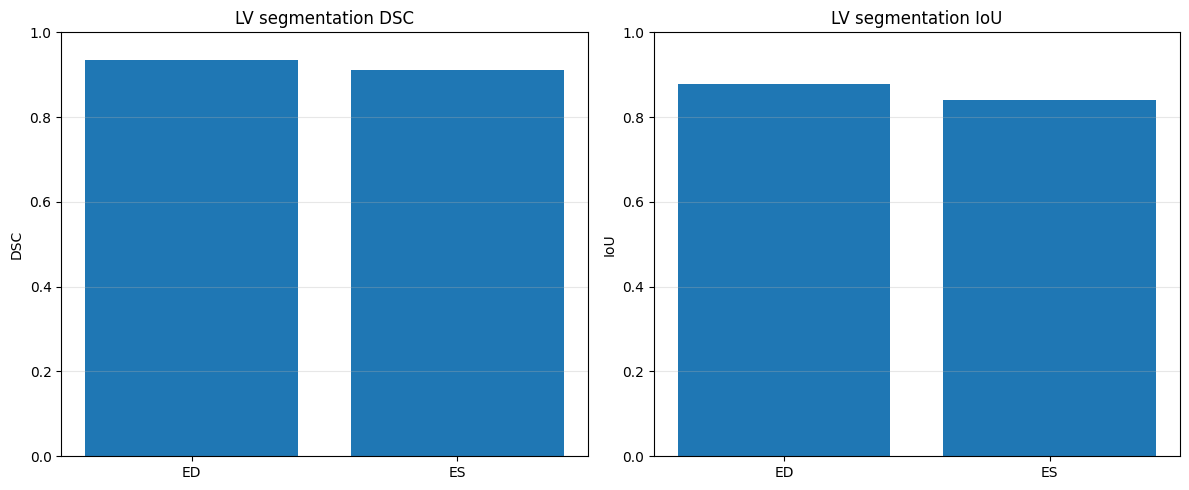

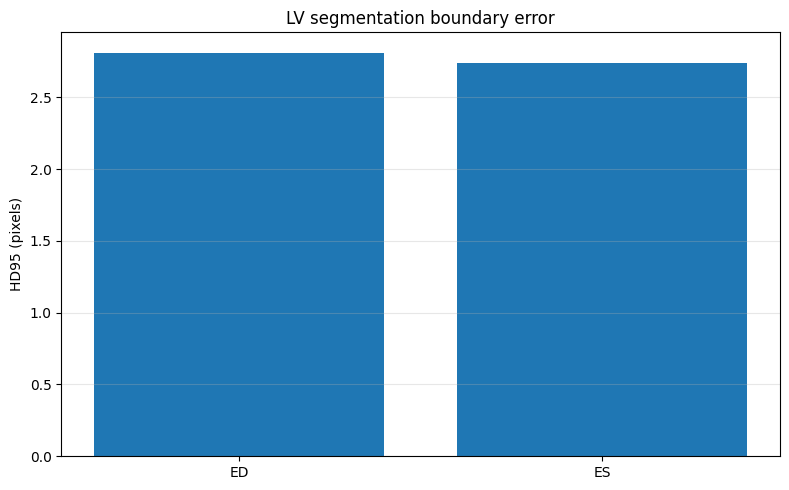

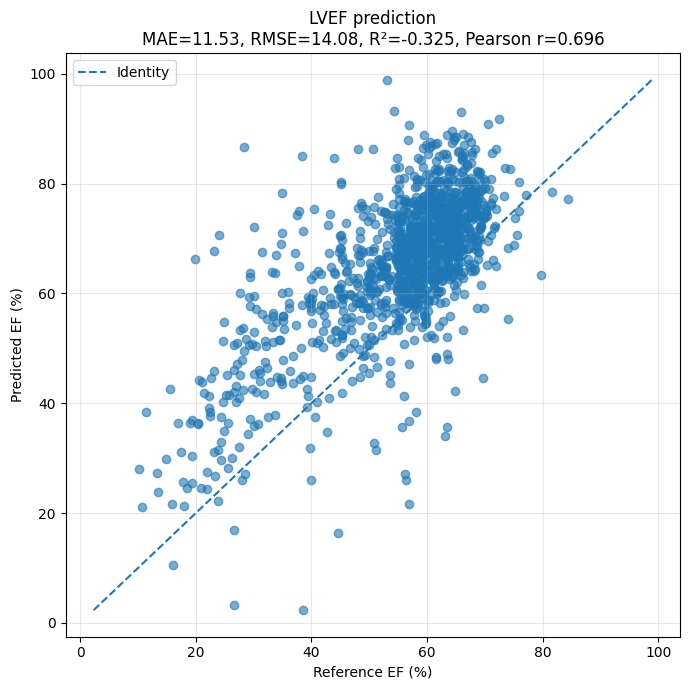

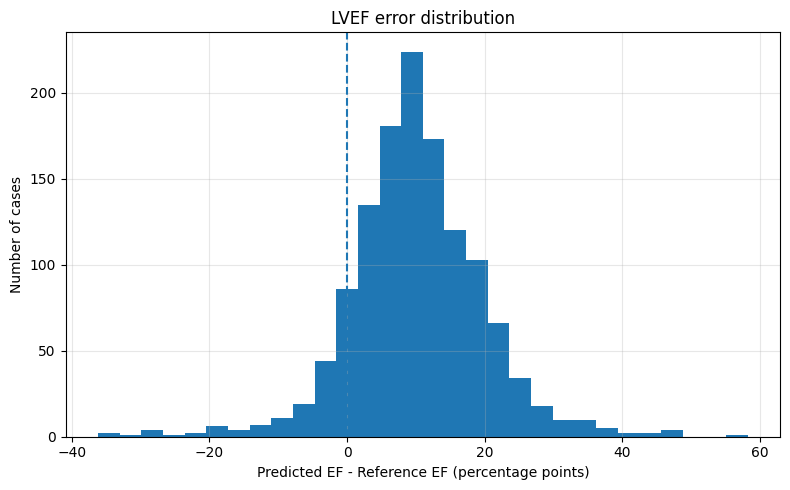

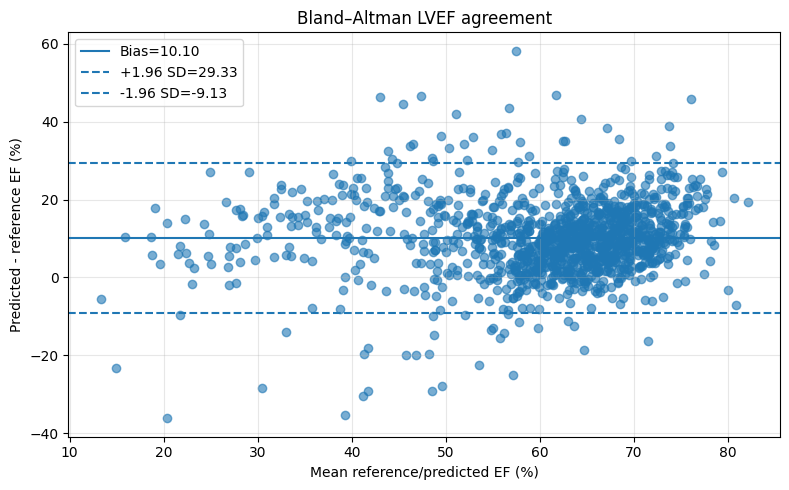

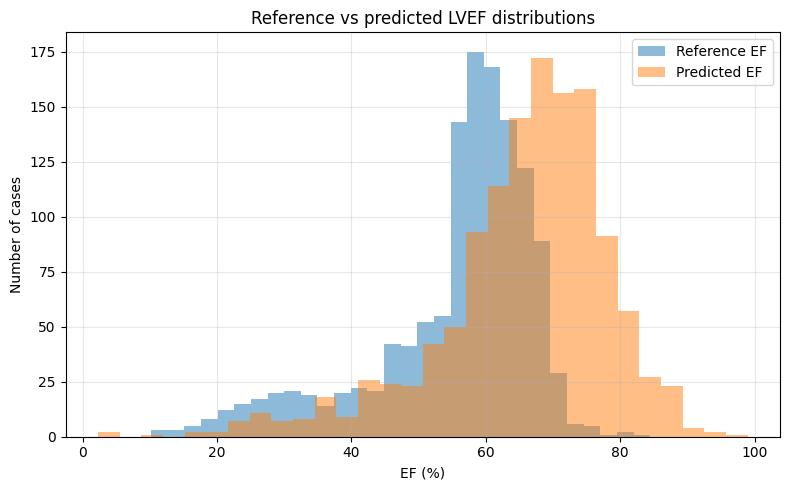

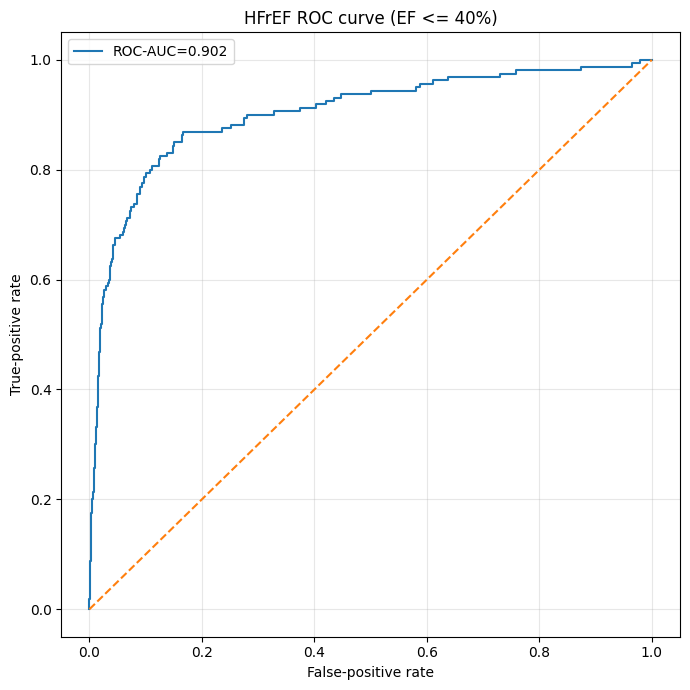

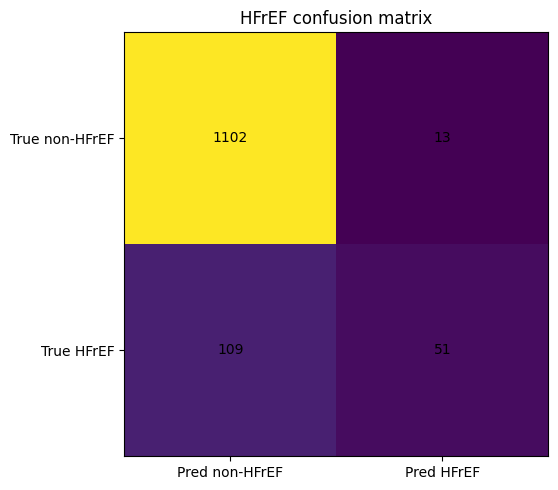

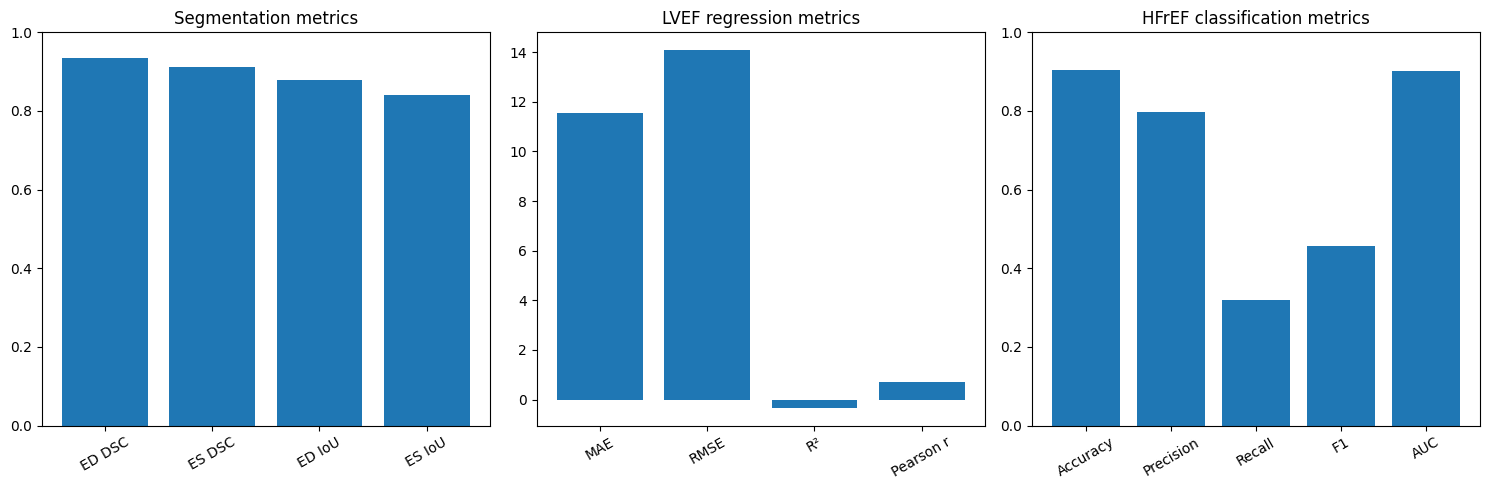

Saved:
  04_segmentation_DSC_IoU.png
  05_segmentation_HD95.png
  06_ef_scatter.png
  07_ef_error_distribution.png
  08_bland_altman_ef.png
  09_ef_distributions.png
  10_hfref_roc.png
  11_hfref_confusion_matrix.png
  12_metric_summary.png



In [20]:
# ============================================================
# 18. EF SCATTER + ERROR DISTRIBUTION
# ============================================================

print("=" * 80)
print("STEP 15 — RESULT GRAPHS")
print("=" * 80)

true_ef = eval_df["TrueEF"].to_numpy(float)
pred_ef = eval_df["PredEF"].to_numpy(float)
ef_err = pred_ef - true_ef

# ------------------------------------------------------------
# LV SEGMENTATION METRICS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

axes[0].bar(
    ["ED", "ES"],
    [mean_ed_dsc, mean_es_dsc]
)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("DSC")
axes[0].set_title("LV segmentation DSC")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    ["ED", "ES"],
    [mean_ed_iou, mean_es_iou]
)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("IoU")
axes[1].set_title("LV segmentation IoU")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "04_segmentation_DSC_IoU.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.bar(
    ["ED", "ES"],
    [mean_ed_hd95, mean_es_hd95]
)

ax.set_ylabel("HD95 (pixels)")
ax.set_title("LV segmentation boundary error")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "05_segmentation_HD95.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# LVEF SCATTER
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 7)
)

ax.scatter(
    true_ef,
    pred_ef,
    alpha=0.6
)

lo = min(
    np.nanmin(true_ef),
    np.nanmin(pred_ef)
)

hi = max(
    np.nanmax(true_ef),
    np.nanmax(pred_ef)
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    label="Identity"
)

ax.set_xlabel("Reference EF (%)")
ax.set_ylabel("Predicted EF (%)")
ax.set_title(
    f"LVEF prediction\n"
    f"MAE={mae_ef:.2f}, "
    f"RMSE={rmse_ef:.2f}, "
    f"R²={r2_ef:.3f}, "
    f"Pearson r={r_ef:.3f}"
)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "06_ef_scatter.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# LVEF ERROR DISTRIBUTION
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.hist(
    ef_err,
    bins=30
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.5
)

ax.set_xlabel(
    "Predicted EF - Reference EF "
    "(percentage points)"
)
ax.set_ylabel("Number of cases")
ax.set_title("LVEF error distribution")
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "07_ef_error_distribution.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# BLAND-ALTMAN
# ------------------------------------------------------------

mean_ef = (
    true_ef
    + pred_ef
) / 2

diff_ef = (
    pred_ef
    - true_ef
)

bias = np.mean(diff_ef)

sd_diff = (
    np.std(
        diff_ef,
        ddof=1
    )
    if len(diff_ef) > 1
    else np.nan
)

loa_upper = (
    bias
    + 1.96 * sd_diff
)

loa_lower = (
    bias
    - 1.96 * sd_diff
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.scatter(
    mean_ef,
    diff_ef,
    alpha=0.6
)

ax.axhline(
    bias,
    linestyle="-",
    label=f"Bias={bias:.2f}"
)

ax.axhline(
    loa_upper,
    linestyle="--",
    label=f"+1.96 SD={loa_upper:.2f}"
)

ax.axhline(
    loa_lower,
    linestyle="--",
    label=f"-1.96 SD={loa_lower:.2f}"
)

ax.set_xlabel(
    "Mean reference/predicted EF (%)"
)

ax.set_ylabel(
    "Predicted - reference EF (%)"
)

ax.set_title(
    "Bland–Altman LVEF agreement"
)

ax.grid(
    True,
    alpha=0.3
)

ax.legend()

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "08_bland_altman_ef.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# LVEF DISTRIBUTIONS
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.hist(
    true_ef,
    bins=30,
    alpha=0.5,
    label="Reference EF"
)

ax.hist(
    pred_ef,
    bins=30,
    alpha=0.5,
    label="Predicted EF"
)

ax.set_xlabel("EF (%)")
ax.set_ylabel("Number of cases")
ax.set_title(
    "Reference vs predicted LVEF distributions"
)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "09_ef_distributions.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# HFrEF ROC CURVE
# ------------------------------------------------------------

if not np.isnan(auc_hf):

    fpr, tpr, _ = roc_curve(
        y_true_hf,
        hf_score
    )

    fig, ax = plt.subplots(
        figsize=(7, 7)
    )

    ax.plot(
        fpr,
        tpr,
        label=f"ROC-AUC={auc_hf:.3f}"
    )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    ax.set_xlabel(
        "False-positive rate"
    )

    ax.set_ylabel(
        "True-positive rate"
    )

    ax.set_title(
        f"HFrEF ROC curve "
        f"(EF <= {HFrEF_THRESHOLD:.0f}%)"
    )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend()

    plt.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "10_hfref_roc.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()

# ------------------------------------------------------------
# HFrEF CONFUSION MATRIX
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6, 5)
)

ax.imshow(
    cm_hf
)

ax.set_xticks(
    [0, 1],
    ["Pred non-HFrEF", "Pred HFrEF"]
)

ax.set_yticks(
    [0, 1],
    ["True non-HFrEF", "True HFrEF"]
)

ax.set_title(
    "HFrEF confusion matrix"
)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm_hf[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "11_hfref_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# METRIC SUMMARY
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

axes[0].bar(
    ["ED DSC", "ES DSC", "ED IoU", "ES IoU"],
    [
        mean_ed_dsc,
        mean_es_dsc,
        mean_ed_iou,
        mean_es_iou
    ]
)

axes[0].set_ylim(0, 1)
axes[0].set_title(
    "Segmentation metrics"
)
axes[0].tick_params(
    axis="x",
    rotation=30
)

axes[1].bar(
    ["MAE", "RMSE", "R²", "Pearson r"],
    [
        mae_ef,
        rmse_ef,
        r2_ef,
        r_ef
    ]
)

axes[1].set_title(
    "LVEF regression metrics"
)
axes[1].tick_params(
    axis="x",
    rotation=30
)

axes[2].bar(
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "AUC"
    ],
    [
        accuracy_hf,
        precision_hf,
        recall_hf,
        f1_hf,
        auc_hf
    ]
)

axes[2].set_ylim(0, 1)
axes[2].set_title(
    "HFrEF classification metrics"
)
axes[2].tick_params(
    axis="x",
    rotation=30
)

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "12_metric_summary.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

print("Saved:")
for filename in [
    "04_segmentation_DSC_IoU.png",
    "05_segmentation_HD95.png",
    "06_ef_scatter.png",
    "07_ef_error_distribution.png",
    "08_bland_altman_ef.png",
    "09_ef_distributions.png",
    "10_hfref_roc.png",
    "11_hfref_confusion_matrix.png",
    "12_metric_summary.png",
]:
    print(f"  {filename}")

print()


# Visualize 5 Test Cases

STEP 16 — VISUAL DEMONSTRATION ON 5 TEST CASES
Showing 5 cases.



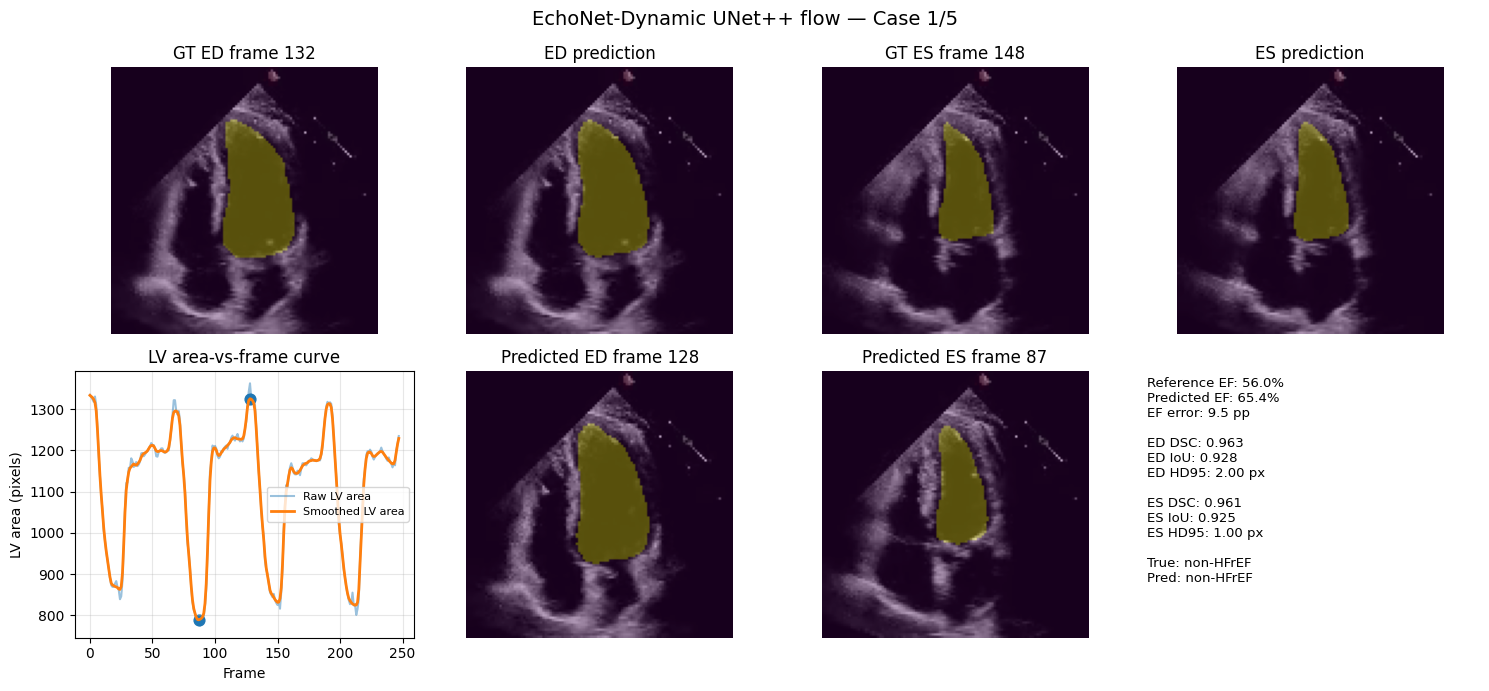

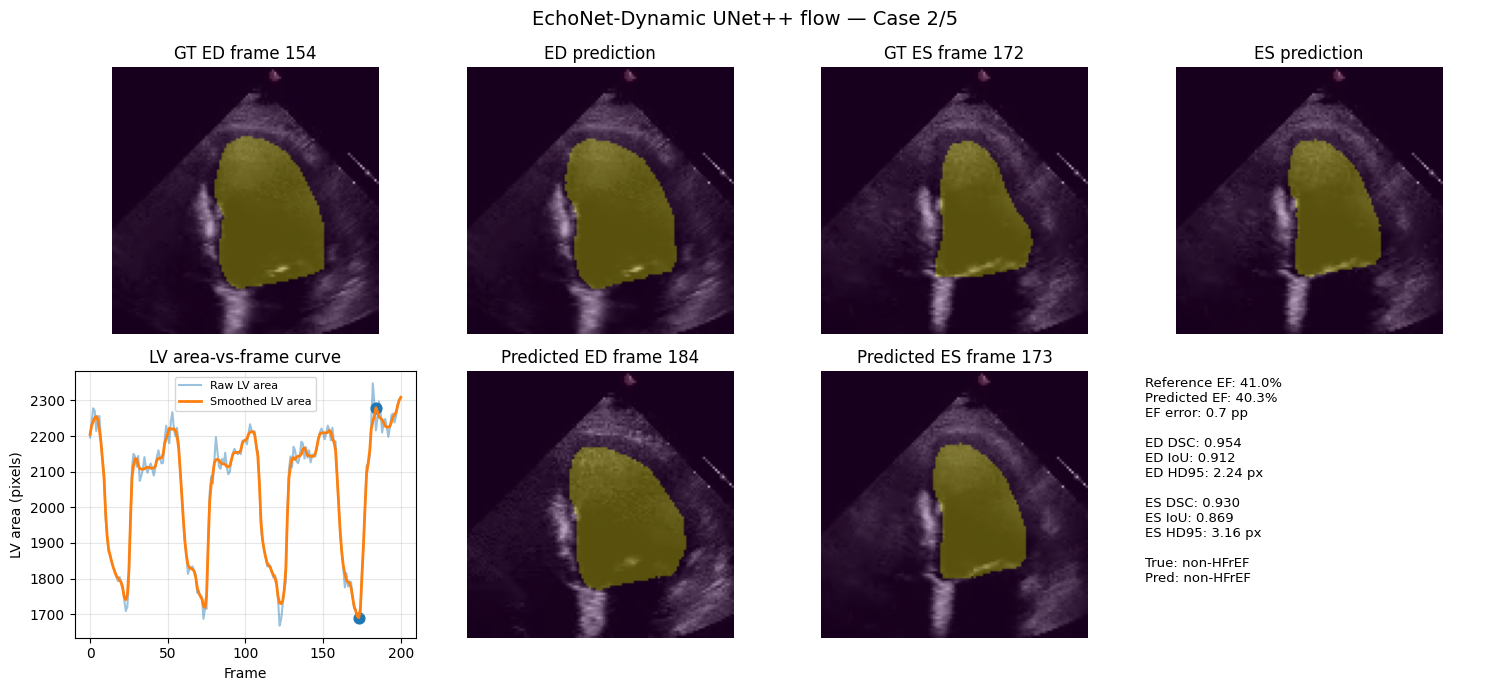

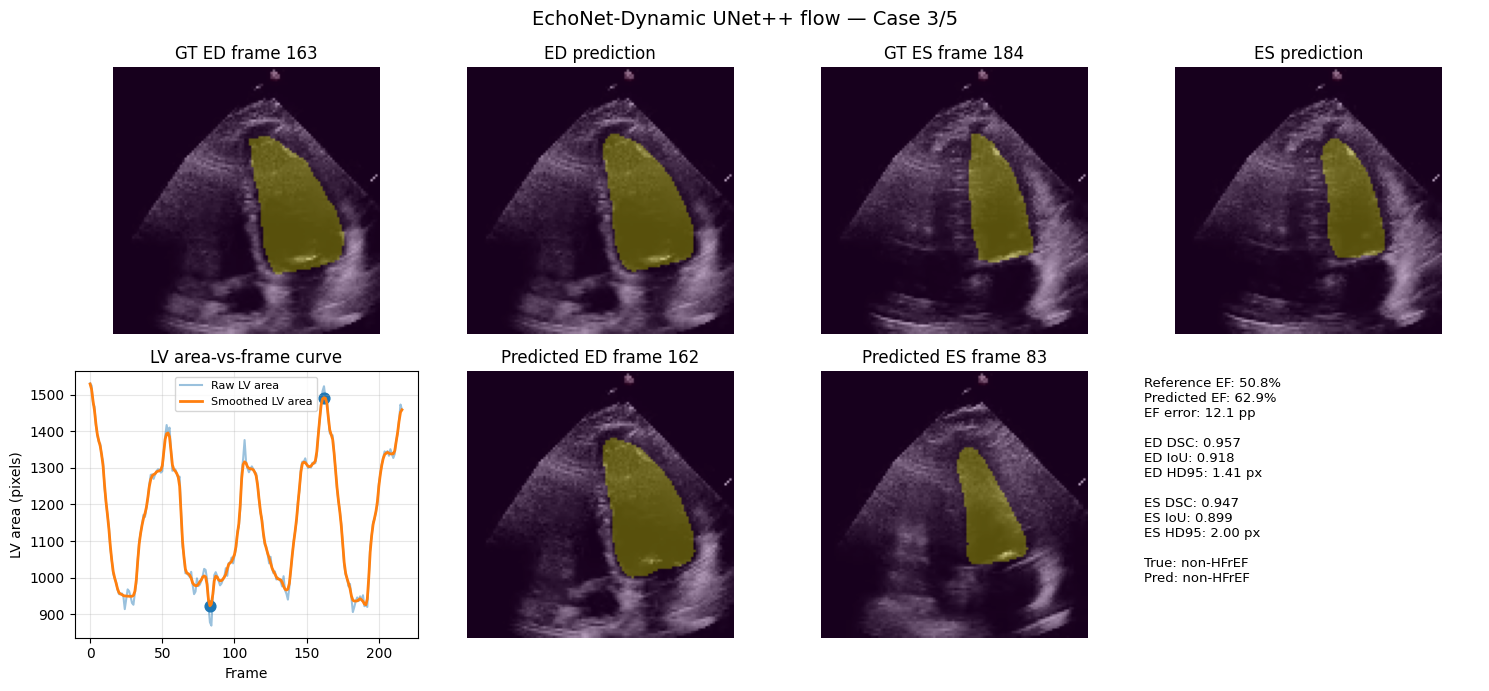

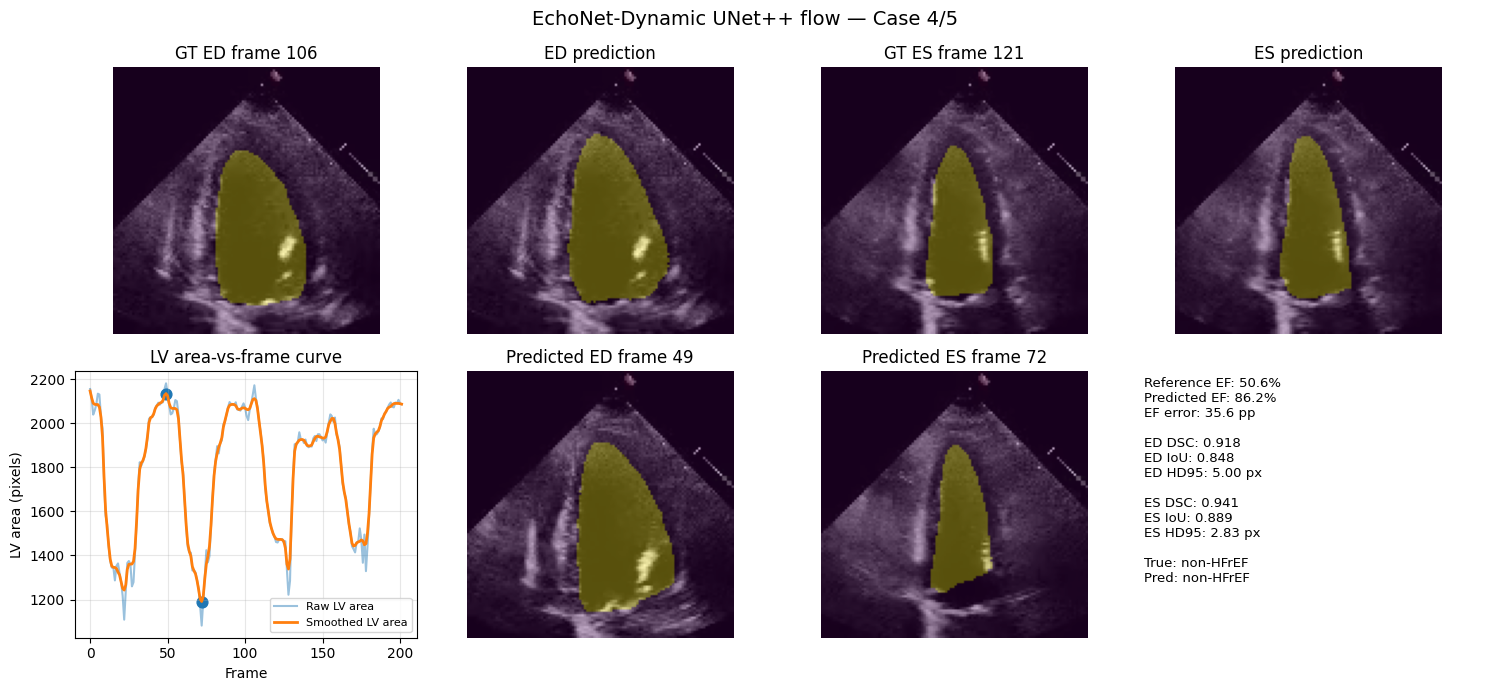

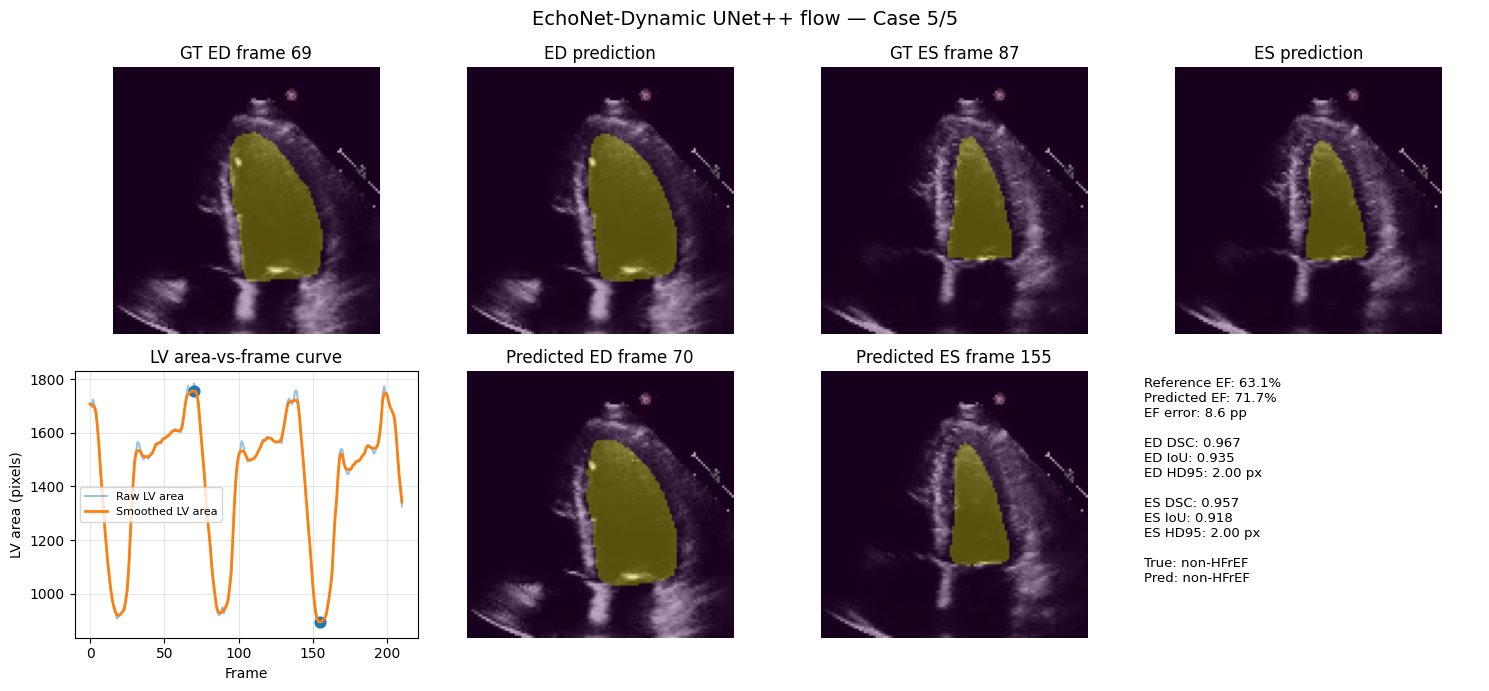

In [21]:
# ============================================================
# 19. VISUALIZE 5 TEST CASES — RAW / GT / PRED / AREA CURVE
# ============================================================

print("=" * 80)
print("STEP 16 — VISUAL DEMONSTRATION ON 5 TEST CASES")
print("=" * 80)

n_show = min(N_VIS, len(visual_cache))
print(f"Showing {n_show} cases.")
print()

for i, case in enumerate(
    visual_cache[:n_show],
    start=1
):
    row = case["row"]
    frames = case["frames"]
    masks = case["masks"]
    areas = case["areas"]
    smooth_area = case["smooth_area"]
    pred_ed = case["pred_ed_frame"]
    pred_es = case["pred_es_frame"]

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(15, 7)
    )

    pred_row = results_df[
        results_df["FileName"] == row.FileName
    ].iloc[0]

    # -------------------------
    # ED: GT
    # -------------------------
    axes[0, 0].imshow(
        frames[row.EDFrame]
    )
    axes[0, 0].imshow(
        row.EDMask,
        alpha=0.35
    )
    axes[0, 0].set_title(
        f"GT ED frame {row.EDFrame}"
    )
    axes[0, 0].axis("off")

    # -------------------------
    # ED: Prediction
    # -------------------------
    axes[0, 1].imshow(
        frames[row.EDFrame]
    )
    axes[0, 1].imshow(
        masks[row.EDFrame],
        alpha=0.35
    )
    axes[0, 1].set_title(
        "ED prediction"
    )
    axes[0, 1].axis("off")

    # -------------------------
    # ES: GT
    # -------------------------
    axes[0, 2].imshow(
        frames[row.ESFrame]
    )
    axes[0, 2].imshow(
        row.ESMask,
        alpha=0.35
    )
    axes[0, 2].set_title(
        f"GT ES frame {row.ESFrame}"
    )
    axes[0, 2].axis("off")

    # -------------------------
    # ES: Prediction
    # -------------------------
    axes[0, 3].imshow(
        frames[row.ESFrame]
    )
    axes[0, 3].imshow(
        masks[row.ESFrame],
        alpha=0.35
    )
    axes[0, 3].set_title(
        "ES prediction"
    )
    axes[0, 3].axis("off")

    # -------------------------
    # LV area curve
    # -------------------------
    axes[1, 0].plot(
        areas,
        alpha=0.45,
        label="Raw LV area"
    )

    axes[1, 0].plot(
        smooth_area,
        linewidth=2,
        label="Smoothed LV area"
    )

    axes[1, 0].scatter(
        [pred_ed, pred_es],
        [
            smooth_area[pred_ed],
            smooth_area[pred_es]
        ],
        s=60
    )

    axes[1, 0].set_xlabel(
        "Frame"
    )

    axes[1, 0].set_ylabel(
        "LV area (pixels)"
    )

    axes[1, 0].set_title(
        "LV area-vs-frame curve"
    )

    axes[1, 0].grid(
        True,
        alpha=0.3
    )

    axes[1, 0].legend(
        fontsize=8
    )

    # -------------------------
    # Predicted ED / mask
    # -------------------------
    axes[1, 1].imshow(
        frames[pred_ed]
    )
    axes[1, 1].imshow(
        masks[pred_ed],
        alpha=0.35
    )
    axes[1, 1].set_title(
        f"Predicted ED frame {pred_ed}"
    )
    axes[1, 1].axis("off")

    # -------------------------
    # Predicted ES / mask
    # -------------------------
    axes[1, 2].imshow(
        frames[pred_es]
    )
    axes[1, 2].imshow(
        masks[pred_es],
        alpha=0.35
    )
    axes[1, 2].set_title(
        f"Predicted ES frame {pred_es}"
    )
    axes[1, 2].axis("off")

    # -------------------------
    # Complete metrics summary
    # -------------------------
    true_hf_label = (
        "HFrEF"
        if int(row.EF <= HFrEF_THRESHOLD)
        else "non-HFrEF"
    )

    pred_hf_label = (
        "HFrEF"
        if int(pred_row.PredEF <= HFrEF_THRESHOLD)
        else "non-HFrEF"
    )

    summary_text = (
        f"Reference EF: {row.EF:.1f}%\n"
        f"Predicted EF: {pred_row.PredEF:.1f}%\n"
        f"EF error: {pred_row.AbsoluteEFError:.1f} pp\n"
        f"\n"
        f"ED DSC: {pred_row.ED_DSC:.3f}\n"
        f"ED IoU: {pred_row.ED_IoU:.3f}\n"
        f"ED HD95: {pred_row.ED_HD95_px:.2f} px\n"
        f"\n"
        f"ES DSC: {pred_row.ES_DSC:.3f}\n"
        f"ES IoU: {pred_row.ES_IoU:.3f}\n"
        f"ES HD95: {pred_row.ES_HD95_px:.2f} px\n"
        f"\n"
        f"True: {true_hf_label}\n"
        f"Pred: {pred_hf_label}"
    )

    axes[1, 3].text(
        0.02,
        0.98,
        summary_text,
        va="top",
        ha="left",
        fontsize=9.5
    )

    axes[1, 3].axis("off")

    fig.suptitle(
        f"EchoNet-Dynamic UNet++ flow — "
        f"Case {i}/{n_show}",
        fontsize=14
    )

    plt.tight_layout()

    fig.savefig(
        OUTPUT_DIR / f"13_visual_case_{i}.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

print()


# Schematic Flowchart

STEP 17 — SCHEMATIC FLOWCHART


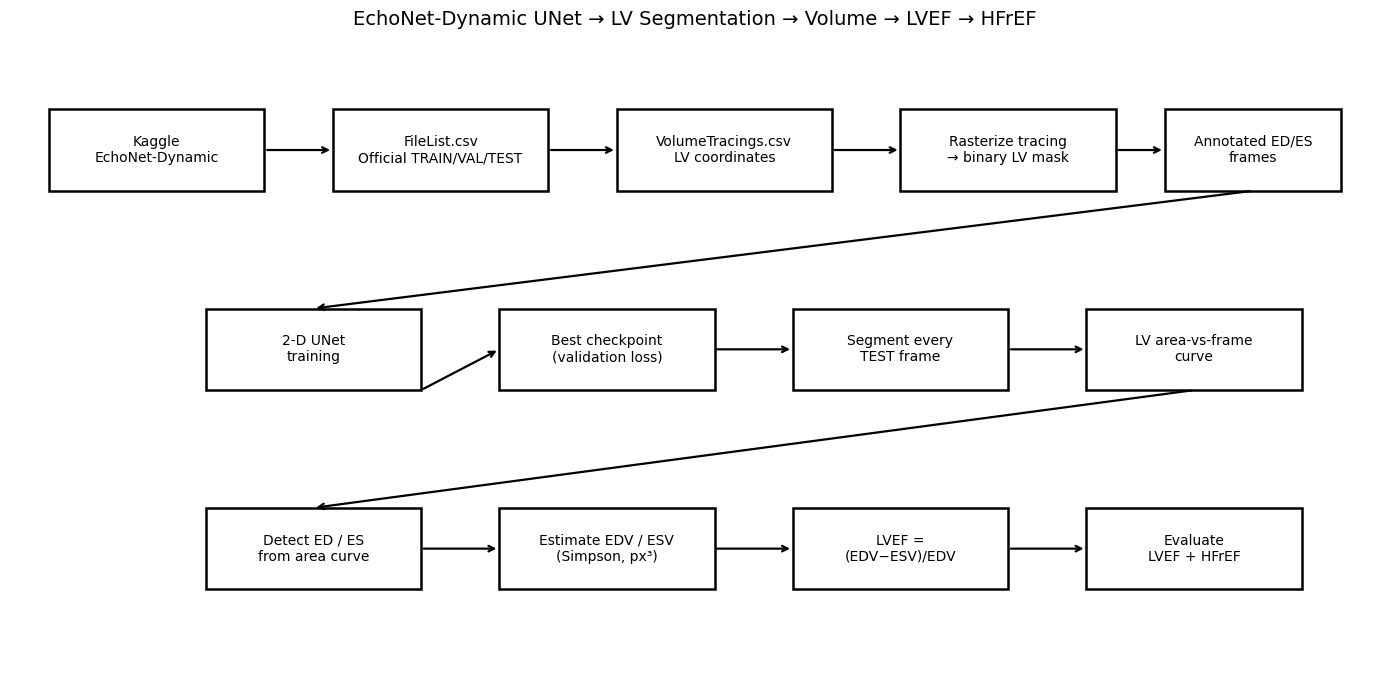

Saved: /kaggle/working/echonet_unet_results/14_flowchart.png



In [22]:
# ============================================================
# 20. SCHEMATIC FLOWCHART
# ============================================================

print("=" * 80)
print("STEP 17 — SCHEMATIC FLOWCHART")
print("=" * 80)

def add_box(ax, x, y, w, h, text, fontsize=10):
    rect = plt.Rectangle(
        (x, y),
        w,
        h,
        fill=False,
        linewidth=1.8
    )

    ax.add_patch(rect)

    ax.text(
        x + w/2,
        y + h/2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize
    )


def add_arrow(ax, x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.6
        )
    )


fig, ax = plt.subplots(
    figsize=(14, 7)
)

ax.set_xlim(0, 14)
ax.set_ylim(0, 7)
ax.axis("off")

boxes = [
    (
        0.4, 5.4, 2.2, 0.9,
        "Kaggle\nEchoNet-Dynamic"
    ),
    (
        3.3, 5.4, 2.2, 0.9,
        "FileList.csv\nOfficial TRAIN/VAL/TEST"
    ),
    (
        6.2, 5.4, 2.2, 0.9,
        "VolumeTracings.csv\nLV coordinates"
    ),
    (
        9.1, 5.4, 2.2, 0.9,
        "Rasterize tracing\n→ binary LV mask"
    ),
    (
        11.8, 5.4, 1.8, 0.9,
        "Annotated ED/ES\nframes"
    ),
    (
        2.0, 3.2, 2.2, 0.9,
        "2-D UNet\ntraining"
    ),
    (
        5.0, 3.2, 2.2, 0.9,
        "Best checkpoint\n(validation loss)"
    ),
    (
        8.0, 3.2, 2.2, 0.9,
        "Segment every\nTEST frame"
    ),
    (
        11.0, 3.2, 2.2, 0.9,
        "LV area-vs-frame\ncurve"
    ),
    (
        2.0, 1.0, 2.2, 0.9,
        "Detect ED / ES\nfrom area curve"
    ),
    (
        5.0, 1.0, 2.2, 0.9,
        "Estimate EDV / ESV\n(Simpson, px³)"
    ),
    (
        8.0, 1.0, 2.2, 0.9,
        "LVEF =\n(EDV−ESV)/EDV"
    ),
    (
        11.0, 1.0, 2.2, 0.9,
        "Evaluate\nLVEF + HFrEF"
    ),
]

for b in boxes:
    add_box(
        ax,
        *b
    )

# Arrows
add_arrow(
    ax,
    2.6,
    5.85,
    3.3,
    5.85
)

add_arrow(
    ax,
    5.5,
    5.85,
    6.2,
    5.85
)

add_arrow(
    ax,
    8.4,
    5.85,
    9.1,
    5.85
)

add_arrow(
    ax,
    11.3,
    5.85,
    11.8,
    5.85
)

add_arrow(
    ax,
    12.7,
    5.4,
    3.1,
    4.1
)

add_arrow(
    ax,
    4.2,
    3.2,
    5.0,
    3.65
)

add_arrow(
    ax,
    7.2,
    3.65,
    8.0,
    3.65
)

add_arrow(
    ax,
    10.2,
    3.65,
    11.0,
    3.65
)

add_arrow(
    ax,
    12.1,
    3.2,
    3.1,
    1.9
)

add_arrow(
    ax,
    4.2,
    1.45,
    5.0,
    1.45
)

add_arrow(
    ax,
    7.2,
    1.45,
    8.0,
    1.45
)

add_arrow(
    ax,
    10.2,
    1.45,
    11.0,
    1.45
)

ax.set_title(
    "EchoNet-Dynamic UNet → LV Segmentation → "
    "Volume → LVEF → HFrEF",
    fontsize=14,
    pad=15
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "14_flowchart.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: "
    f"{OUTPUT_DIR / '14_flowchart.png'}"
)
print()


# Final Summary

In [23]:
# ============================================================
# 21. FINAL SUMMARY
# ============================================================

print("=" * 80)
print("STEP 18 — FINAL SUMMARY")
print("=" * 80)

print(
    f"Dataset root:              {DATA_ROOT}"
)

print(
    f"Train studies used:        "
    f"{len(train_meta):,}"
)

print(
    f"Validation studies used:   "
    f"{len(val_meta):,}"
)

print(
    f"Test studies evaluated:    "
    f"{len(eval_df):,}"
)

print()

print("LV SEGMENTATION")
print(
    f"  ED DSC:       {mean_ed_dsc:.4f}"
)
print(
    f"  ES DSC:       {mean_es_dsc:.4f}"
)
print(
    f"  ED IoU:       {mean_ed_iou:.4f}"
)
print(
    f"  ES IoU:       {mean_es_iou:.4f}"
)
print(
    f"  ED HD95:      {mean_ed_hd95:.3f} px"
)
print(
    f"  ES HD95:      {mean_es_hd95:.3f} px"
)

print()

print("LVEF PREDICTION")
print(
    f"  MAE:          "
    f"{mae_ef:.3f} percentage points"
)
print(
    f"  RMSE:         "
    f"{rmse_ef:.3f} percentage points"
)
print(
    f"  R²:           "
    f"{r2_ef:.4f}"
)
print(
    f"  Pearson r:    "
    f"{r_ef:.4f}"
)

print()

print("HFrEF CLASSIFICATION")
print(
    f"  Threshold:    "
    f"LVEF <= {HFrEF_THRESHOLD:.0f}%"
)
print(
    f"  Accuracy:     "
    f"{accuracy_hf:.4f}"
)
print(
    f"  Precision:    "
    f"{precision_hf:.4f}"
)
print(
    f"  Recall:       "
    f"{recall_hf:.4f}"
)
print(
    f"  F1:           "
    f"{f1_hf:.4f}"
)
print(
    f"  ROC-AUC:      "
    f"{auc_hf:.4f}"
)

print()

print("All final outputs are in:")
print(
    f"  {OUTPUT_DIR}"
)

print()

print("Key outputs:")
for filename in [
    "best_unet.pt",
    "test_results.csv",
    "metrics_summary.csv",
    "01_ground_truth_examples.png",
    "02_training_loss.png",
    "03_validation_metrics.png",
    "04_segmentation_DSC_IoU.png",
    "05_segmentation_HD95.png",
    "06_ef_scatter.png",
    "07_ef_error_distribution.png",
    "08_bland_altman_ef.png",
    "09_ef_distributions.png",
    "10_hfref_roc.png",
    "11_hfref_confusion_matrix.png",
    "12_metric_summary.png",
    "13_visual_case_1.png ... 13_visual_case_N.png",
    "14_flowchart.png",
]:
    print(
        f"  {filename}"
    )

print()
print("DONE.")


STEP 18 — FINAL SUMMARY
Dataset root:              /kaggle/input/datasets/manojkumarcs28/echonet-dynamic-by-stanford-university/EchoNet-Dynamic
Train studies used:        7,460
Validation studies used:   1,288
Test studies evaluated:    1,275

LV SEGMENTATION
  ED DSC:       0.9347
  ES DSC:       0.9121
  ED IoU:       0.8789
  ES IoU:       0.8415
  ED HD95:      2.812 px
  ES HD95:      2.737 px

LVEF PREDICTION
  MAE:          11.532 percentage points
  RMSE:         14.076 percentage points
  R²:           -0.3254
  Pearson r:    0.6957

HFrEF CLASSIFICATION
  Threshold:    LVEF <= 40%
  Accuracy:     0.9043
  Precision:    0.7969
  Recall:       0.3187
  F1:           0.4554
  ROC-AUC:      0.9018

All final outputs are in:
  /kaggle/working/echonet_unet_results

Key outputs:
  best_unet.pt
  test_results.csv
  metrics_summary.csv
  01_ground_truth_examples.png
  02_training_loss.png
  03_validation_metrics.png
  04_segmentation_DSC_IoU.png
  05_segmentation_HD95.png
  06_ef_scat